# Análisis conjunto — Bases A, B y C
## Observatorio de Financiamiento y Endeudamiento en Argentina
**Versión 1 · 24 de septiembre de 2026 · Proyecto Final, Licenciatura en Ciencia de Datos**

**Objetivo:** describir la evolución del crédito, la estructura de las ofertas publicadas y el endeudamiento del panel empresarial. La unidad narrativa es común; cada base conserva su grano, población y calendario.

### Recorrido
1. Alcance y configuración reproducible.
2. **A:** stocks, composición, tasas y asociaciones descriptivas.
3. **B:** dispersión de ofertas, requisitos, entidades y evolución agregada.
4. **C:** exposición, concentración, situaciones y trayectorias del panel.
5. Síntesis, límites y preguntas para la etapa siguiente.

El paquete incluye los datos recibidos, el catálogo editable en `config/catalogo_base_a.csv` y un adaptador en `lib/eda.py` que reutiliza las funciones de los tres pipelines. Ejecutar **Restart Kernel → Run All**. Los cuadros y figuras se regeneran en `analisis/resultados/`. El análisis no llama APIs.

## 0. Contrato metodológico

| Base | Unidad | Regla principal |
|---|---|---|
| A | Serie × fecha | Comparar unidades y frecuencias compatibles; separar ML/ME; valores nominales |
| B | Registro publicado × snapshot | Estratificar por familia, denominación y tipo de tasa; contar registros, no ofertas únicas |
| C | CUIT × entidad × mes; CUIT × mes | Exposición sobre saldos positivos; reporting conserva todas las filas |

- A: las tasas diarias se resumen por media de observaciones del mes. Se conserva el número de observaciones; el mes abierto queda identificado. Los meses faltantes se mantienen como NA. Las variaciones son descriptivas y no implican crecimiento real.
- B: una TEA en UVA no mide el costo total de un préstamo en pesos fijos. Tarjetas utiliza TEA de financiación; la de adelantos es otra variable. CFTEA y TNA no se fabrican cuando no están publicadas. Los extremos y ceros publicados permanecen en las distribuciones; se muestra sensibilidad a información de hasta 365 días.
- C: `monto=0` significa ausencia de saldo positivo **informado en esa fila**. Un mes sin observación no equivale a cero. La situación principal es el máximo entre saldos positivos, y queda NA sin deuda positiva o con clasificación activa desconocida. HHI y participaciones quedan NA cuando el denominador es cero.
- La muestra C es intencional; sus porcentajes describen este panel. Las pertenencias sectoriales se superponen y no deben sumarse para estimar el total.
- Las asociaciones no identifican causalidad. Los resultados no son un score, un target final ni una recomendación crediticia.

In [1]:
from pathlib import Path
import sys, json, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display, Markdown
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'lib/common.py').is_file())
SUPPORT = PROJECT_ROOT
if str(SUPPORT) not in sys.path:
    sys.path.insert(0, str(SUPPORT))
from lib import eda

# Indicar aquí una carpeta que contenga data_a, data_b y data_c, o dejar None.
# Ejemplo Windows: Path(r"C:\Users\Asus\...\scripts")
DATA_ROOT = None
RUN_C = eda.CANONICAL_C  # None: run completo con mayor universo; explicitar para reproducir.
RECENT_START = '2024-01-01'
HERE = PROJECT_ROOT / 'analisis'
ROOT = eda.resolve_data_root(DATA_ROOT, HERE)
OUT = HERE / 'resultados'
(OUT / 'figuras').mkdir(parents=True, exist_ok=True)
SOURCE_HASHES = eda.fingerprint(ROOT)
pd.set_option('display.max_columns', 18)
pd.set_option('display.max_rows', 24)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
sns.set_theme(style='whitegrid', palette='colorblind', font_scale=0.95)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'axes.spines.top':False, 'axes.spines.right':False})

def table(df, name, rows=16):
    eda.save_table(df, name, OUT)
    display(df.head(rows))
    if len(df) > rows:
        print(f'{len(df):,} filas en analisis/resultados/tablas/{name}.csv; vista: primeras {rows}.')

def figsave(fig, name):
    for ax in fig.axes:
        if isinstance(ax.xaxis.get_major_locator(), mdates.DateLocator):
            locator=mdates.AutoDateLocator(minticks=3,maxticks=6)
            ax.xaxis.set_major_locator(locator)
            ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    fig.tight_layout()
    fig.savefig(OUT / 'figuras' / f'{name}.png', bbox_inches='tight')
    display(fig)
    plt.close(fig)

def say(s): display(Markdown(s))

a, catalog, a_monthly, aw, fx = eda.load_a(ROOT, ROOT/'config/catalogo_base_a.csv')
b, b_inventory, b_exclusions = eda.load_b(ROOT)
run_c, master, links, coverage, c_long, c_active, cp = eda.load_c(ROOT, RUN_C)
latest_sid = b.snapshot_id.max()
bl = b[b.snapshot_id.eq(latest_sid)].copy()
bd = b[b.seleccionado_dia].copy()
say(f'**Insumos:** A: {len(a):,} observaciones / {len(catalog)} series; '
    f'B: {b.snapshot_id.nunique()} snapshots completos; '
    f'C: {len(master)} empresas / {len(cp):,} empresa-mes. Run C: `{run_c.name}`.')

**Insumos:** A: 41,687 observaciones / 65 series; B: 13 snapshots completos; C: 100 empresas / 2,400 empresa-mes. Run C: `20260910_234243_324893`.

In [2]:
scope = pd.DataFrame([
    ['A', 'Serie × fecha', a.fecha.min(), a.fecha.max(), a.idVariable.nunique()],
    ['B', 'Registro × snapshot', b.snapshot_date.min(), b.snapshot_date.max(), b.snapshot_id.nunique()],
    ['C', 'CUIT × mes', cp.fecha.min(), cp.fecha.max(), len(master)],
], columns=['base','grano','desde','hasta','n_unidades_o_snapshots'])
table(scope, '00_alcance')
table(b_inventory, '00_snapshots_b', rows=20)
overlap_bc = set(b.snapshot_date.dt.to_period('M')) & set(cp.fecha.dt.to_period('M'))
say(f'**B–C:** {len(overlap_bc)} meses de solapamiento observado. '
    'Las fechas corresponden a captura de oferta (B) y período de deuda (C), respectivamente.')
availability = pd.DataFrame([
    ['A','Crédito por titular, hipotecario y prendario','Disponible'],
    ['A','Stocks de personales/tarjetas por línea','No disponibles; sí hay tasas'],
    ['A','Stocks de depósitos / agregados monetarios','No disponibles en el insumo'],
    ['A','Evolución cambiaria',f'{len(fx)} cotización(es); no alcanza para una serie histórica'],
    ['B','TEA','Préstamos: TEA máxima; tarjetas: TEA máxima de financiación'],
    ['B','CFTEA','Disponible en préstamos; ausente en tarjetas'],
    ['B','TNA','No publicada en estos archivos'],
    ['C','Región / tamaño económico','No hay variables estructuradas suficientes; deuda no equivale a tamaño'],
], columns=['base','pregunta_o_variable','alcance'])
table(availability, '00_disponibilidad', rows=20)

,base,grano,desde,hasta,n_unidades_o_snapshots
0,A,Serie × fecha,1943-03-31,2026-09-10,65
1,B,Registro × snapshot,2026-09-07,2026-09-23,13
2,C,CUIT × mes,2024-08-01,2026-07-01,100


,snapshot_id,snapshot_date,completo,motivo,seleccionado_dia
0,20260907_212935_569641,2026-09-07,True,disponible,True
1,20260908_224655_838862,2026-09-08,True,disponible,True
2,20260909_230424_341254,2026-09-09,True,disponible,True
3,20260910_221306_387342,2026-09-10,True,disponible,True
4,20260911_215454_602912,2026-09-11,True,disponible,True
5,20260912_192218_082470,2026-09-12,True,disponible,True
13,20260913_181332_567641,2026-09-13,False,registrado_sin_archivos_fisicos,False
6,20260913_220415_571963,2026-09-13,True,disponible,True
7,20260914_231738_476390,2026-09-14,True,disponible,True
8,20260915_230313_952585,2026-09-15,True,disponible,True


**B–C:** 0 meses de solapamiento observado. Las fechas corresponden a captura de oferta (B) y período de deuda (C), respectivamente.

,base,pregunta_o_variable,alcance
0,A,"Crédito por titular, hipotecario y prendario",Disponible
1,A,Stocks de personales/tarjetas por línea,No disponibles; sí hay tasas
2,A,Stocks de depósitos / agregados monetarios,No disponibles en el insumo
3,A,Evolución cambiaria,1 cotización(es); no alcanza para una serie hi...
4,B,TEA,Préstamos: TEA máxima; tarjetas: TEA máxima de...
5,B,CFTEA,Disponible en préstamos; ausente en tarjetas
6,B,TNA,No publicada en estos archivos
7,C,Región / tamaño económico,No hay variables estructuradas suficientes; de...


# A. Evolución del mercado crediticio
## A1. ¿Cómo evolucionaron los stocks y su composición por titular?

El agregado mostrado suma las cuatro categorías disponibles: personas humanas, prestadoras financieras, PyMEs y no PyMEs. Se rotula como **total de categorías cubiertas**, sin equipararlo automáticamente a todo el sistema. Para graficar se divide el valor publicado por un millón y se muestran **millones de unidades publicadas**.

**Alerta de escala absoluta:** el catálogo declara los stocks seleccionados en miles de ARS. Sin embargo, las series 26/127 del catálogo amplio declaran millones de ARS y muestran órdenes numéricos cercanos al total 883+885+891+892. Las fechas y universos difieren: esto no prueba una conversión concreta, pero requiere verificación de fuente antes de convertir a ARS o comparar montos con C. En esta V1 se conserva la unidad declarada como metadato y se evita afirmar una escala monetaria validada. Las series 26/127 sólo se inspeccionan como metadatos de contraste, no se incorporan como historia analítica.

La historia completa usa escala logarítmica por la amplitud nominal. El panel reciente mantiene escala lineal. Ninguno es una medida de crecimiento real. La desagregación hipotecarios/prendarios se analiza aparte para evitar doble conteo con los totales por titular.

65 filas en outputs/tablas/A_catalogo_analitico.csv; vista: primeras 12.


,serie_id,concepto,descripcion,segmento,unidad,moneda,frecuencia,tipo_valor,rol_eda,nivel_narrativa,agregacion_mensual,nota,validacion_escala
0,7,tasa_badlar_privados,Tasa de interés BADLAR de bancos privados,Contexto,En porcentaje nominal anual,ML,D,tasa_nominal_anual,rates,principal,media_observada,NaN,metadata_declarada
1,14,tasa_prestamos_personales,Tasa de interés de préstamos personales,Contexto,En porcentaje nominal anual,ML,D,tasa_nominal_anual,rates,principal,media_observada,NaN,metadata_declarada
2,27,inflacion_mensual,Inflación mensual.,Contexto,En porcentaje,ML,M,variacion_porcentual,context_inflation,principal,observacion_mensual,NaN,metadata_declarada
3,28,inflacion_interanual,Inflación interanual.,Contexto,En porcentaje,ML,M,variacion_porcentual,context_inflation,principal,observacion_mensual,NaN,metadata_declarada
4,135,tasa_tamar,Tasa de interés TAMAR de bancos públicos y pri...,Contexto,En porcentaje nominal anual,ML,D,tasa_nominal_anual,rates,principal,media_observada,Cambio metodológico 2026 documentado en QA pre...,metadata_declarada
5,145,tasa_adelantos_empresas_privadas_1_7_dias,Tasa de interés de adelantos en cuenta corrien...,Contexto,En porcentaje nominal anual,ML,D,tasa_nominal_anual,rates,principal,media_observada,NaN,metadata_declarada
6,883,prestamos_personas_humanas,Total de préstamos a personas humanas,Personas humanas,En miles de ARS,MEyML,M,stock_nominal,core_credit,principal,observacion_mensual,NaN,pendiente_escala_absoluta
7,885,prestamos_prestadoras_servicios_financieros,Total de préstamos a las prestadoras de servic...,Prestadoras financieras,En miles de ARS,MEyML,M,stock_nominal,core_credit,principal,observacion_mensual,NaN,pendiente_escala_absoluta
8,891,prestamos_pymes,Total de préstamos a pequeños y medianos empre...,PyMEs,En miles de ARS,MEyML,M,stock_nominal,core_credit,principal,observacion_mensual,NaN,pendiente_escala_absoluta
9,892,prestamos_empresas_no_pymes,Total de préstamos a las empresas no constitui...,No PyMEs,En miles de ARS,MEyML,M,stock_nominal,core_credit,principal,observacion_mensual,NaN,pendiente_escala_absoluta


,idVariable,descripcion,unidadExpresion,moneda,ultFechaInformada,ultValorInformado
19,26,Préstamos de las entidades financieras al sect...,En millones de ARS,MEyML,2026-09-09,"142,649,118.000"
112,127,Préstamos otorgados al sector privado,En millones de ARS,MEyML,2026-09-08,"141,326,583.075"
861,883,Total de préstamos a personas humanas,En miles de ARS,MEyML,2026-06-30,"65,403,148.000"
862,884,Total de préstamos a personas jurídicas,En miles de ARS,MEyML,2026-06-30,"73,341,532.000"
863,885,Total de préstamos a las prestadoras de servic...,En miles de ARS,MEyML,2026-06-30,"125,490.000"
869,891,Total de préstamos a pequeños y medianos empre...,En miles de ARS,MEyML,2026-06-30,"31,380,891.000"
870,892,Total de préstamos a las empresas no constitui...,En miles de ARS,MEyML,2026-06-30,"41,835,151.000"


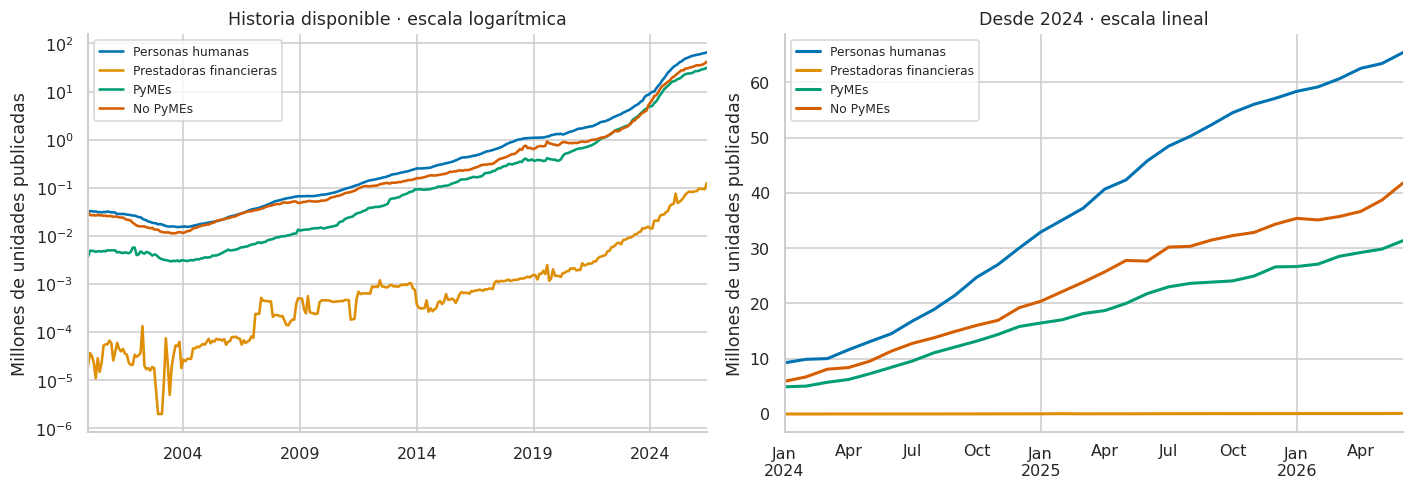

,segmento,inicio,ultimo,fecha_ultimo,participacion_ultimo_pct
0,Personas humanas,"30,045.000","65,403,148.000",2026-06-30,47.139
1,Prestadoras financieras,20.000,"125,490.000",2026-06-30,0.090
2,PyMEs,"3,669.000","31,380,891.000",2026-06-30,22.618
3,No PyMEs,"31,588.000","41,835,151.000",2026-06-30,30.153


**Lectura:** al 2026-06, las categorías cubiertas suman 138.74 millones de unidades publicadas. El mayor segmento es **Personas humanas**. La comparación temporal incorpora inflación y cambios de valuación.

In [3]:
table(catalog, 'A_catalogo_analitico', rows=12)
unit_reference=eda.read_csv(ROOT/'data_a/metadata/bcra_monetarias_catalog.csv')
unit_reference=unit_reference[unit_reference.idVariable.isin([26,127,883,884,885,891,892])]
unit_cols=[x for x in ['idVariable','descripcion','unidadExpresion','moneda','ultFechaInformada','ultValorInformado'] if x in unit_reference]
table(unit_reference[unit_cols],'A0_alerta_escala_metadata',rows=12)
stocks = aw[list(eda.SEGMENTS)].dropna(how='all').rename(columns=eda.SEGMENTS)
stock_total = stocks.sum(axis=1, min_count=4)
stocks_full = stocks.reindex(pd.date_range(stocks.index.min(), stocks.index.max(), freq='ME'))
recent = stocks_full.loc[RECENT_START:]
fig, axes = plt.subplots(1,2, figsize=(13,4.6))
(stocks_full/1e6).plot(ax=axes[0], logy=True, linewidth=1.7)
(recent/1e6).plot(ax=axes[1], linewidth=2)
axes[0].set_title('Historia disponible · escala logarítmica')
axes[1].set_title('Desde 2024 · escala lineal')
for ax in axes: ax.set_ylabel('Millones de unidades publicadas'); ax.set_xlabel('')
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
figsave(fig,'A1_stock_credito')
stock_summary = pd.DataFrame({'inicio':stocks.apply(lambda s:s.dropna().iloc[0]),
                              'ultimo':stocks.apply(lambda s:s.dropna().iloc[-1]),
                              'fecha_ultimo':stocks.apply(lambda s:s.last_valid_index())})
stock_summary['participacion_ultimo_pct'] = stocks.loc[stocks.dropna().index.max()] / stock_total.dropna().iloc[-1] * 100
table(stock_summary.reset_index(names='segmento'), 'A1_ultimo_stock')
say(f'**Lectura:** al {stocks.dropna().index.max():%Y-%m}, las categorías cubiertas suman '
    f'{stock_total.dropna().iloc[-1]/1e6:,.2f} millones de unidades publicadas. '
    f'El mayor segmento es **{stock_summary.ultimo.idxmax()}**. La comparación temporal incorpora inflación y cambios de valuación.')

30 filas en outputs/tablas/A2_composicion_titular.csv; vista: primeras 8.


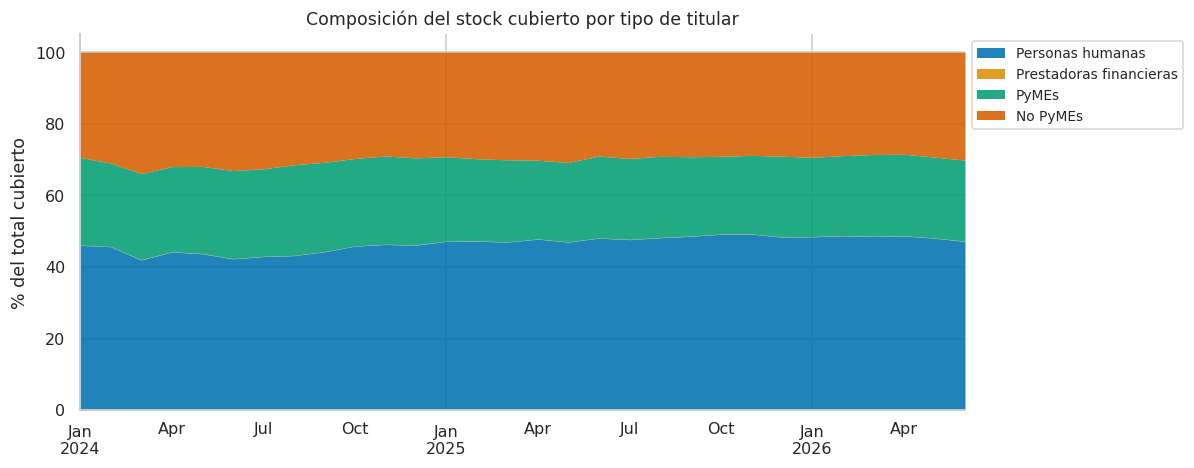

idVariable,fecha,Personas humanas,Prestadoras financieras,PyMEs,No PyMEs
0,2024-01-31,46.025,0.071,24.495,29.409
1,2024-02-29,45.654,0.066,23.296,30.984
2,2024-03-31,41.938,0.086,24.047,33.929
3,2024-04-30,44.189,0.079,23.763,31.968
4,2024-05-31,43.685,0.069,24.335,31.912
5,2024-06-30,42.263,0.076,24.589,33.072
6,2024-07-31,42.886,0.071,24.461,32.583
7,2024-08-31,43.166,0.064,25.290,31.481


Entre 2024-01 y 2026-06, **Personas humanas** ganó 1.11 puntos porcentuales de participación. Es un cambio de composición dentro de estas cuatro categorías.

In [4]:
composition = recent.div(recent.sum(axis=1, min_count=4), axis=0)*100
fig, ax = plt.subplots(figsize=(11,4.4))
composition.plot.area(ax=ax, linewidth=0, alpha=.88)
ax.set(title='Composición del stock cubierto por tipo de titular', ylabel='% del total cubierto', xlabel='')
ax.legend(loc='upper left', bbox_to_anchor=(1,1), fontsize=9)
figsave(fig,'A2_composicion_titular')
table(composition.reset_index(names='fecha'), 'A2_composicion_titular', rows=8)
delta_shares = composition.iloc[-1]-composition.iloc[0]
say(f'Entre {composition.index[0]:%Y-%m} y {composition.index[-1]:%Y-%m}, '
    f'**{delta_shares.idxmax()}** ganó {delta_shares.max():.2f} puntos porcentuales de participación. '
    'Es un cambio de composición dentro de estas cuatro categorías.')

## A2. ¿Qué muestran hipotecarios y prendarios, por moneda y destino?

ML y ME conservan sus aperturas originales. La unidad declarada de ambas es miles de ARS, con la alerta de escala indicada en A1: **ME no equivale a un saldo expresado en dólares**. No se reconstruye MEyML sumando ML+ME, de acuerdo con las reconciliaciones anteriores. Los destinos de personas humanas son aperturas del total correspondiente y no se agregan encima de él.

30 filas en outputs/tablas/A4_destinos_hipotecarios.csv; vista: primeras 16.


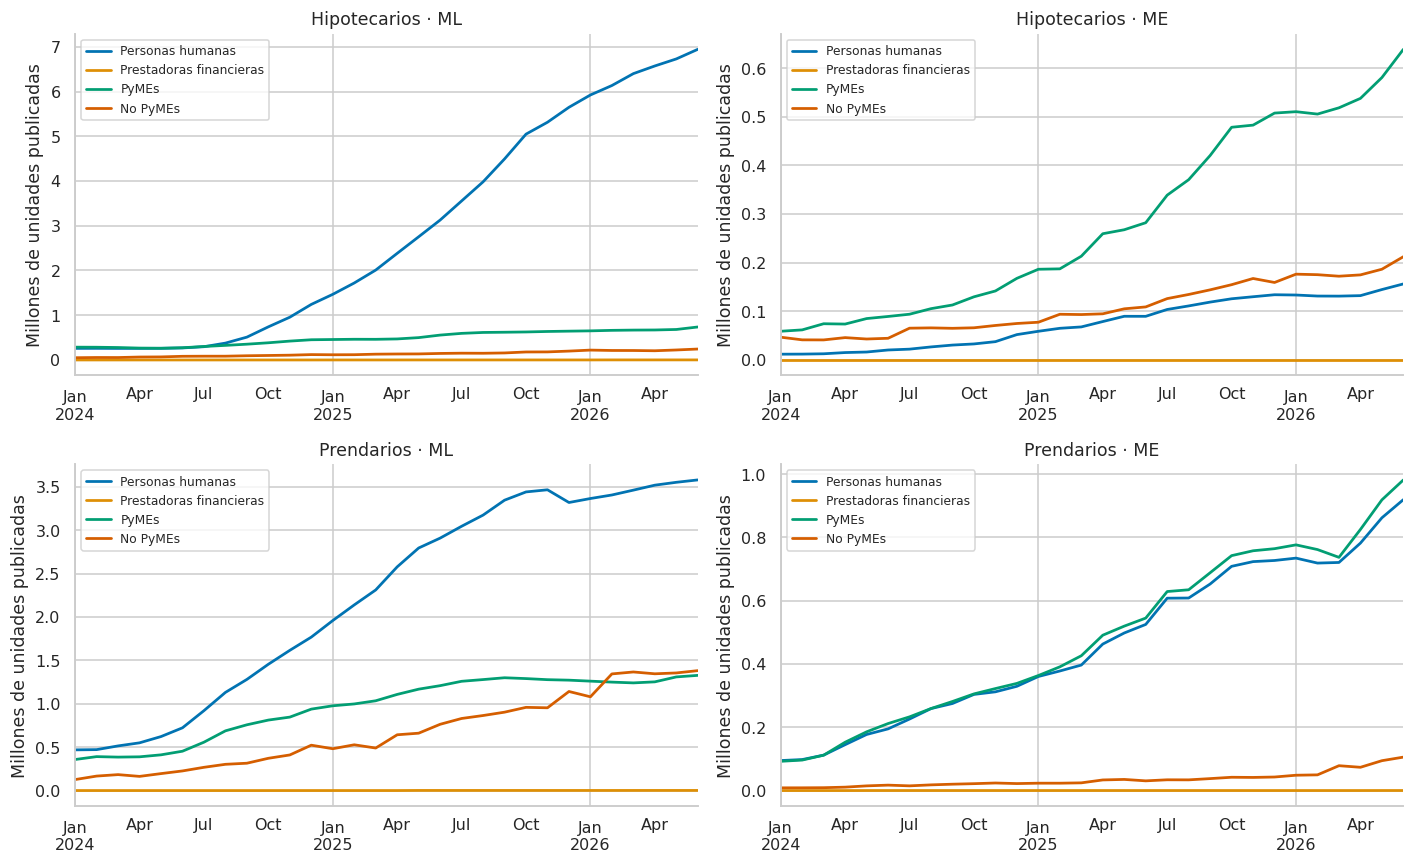

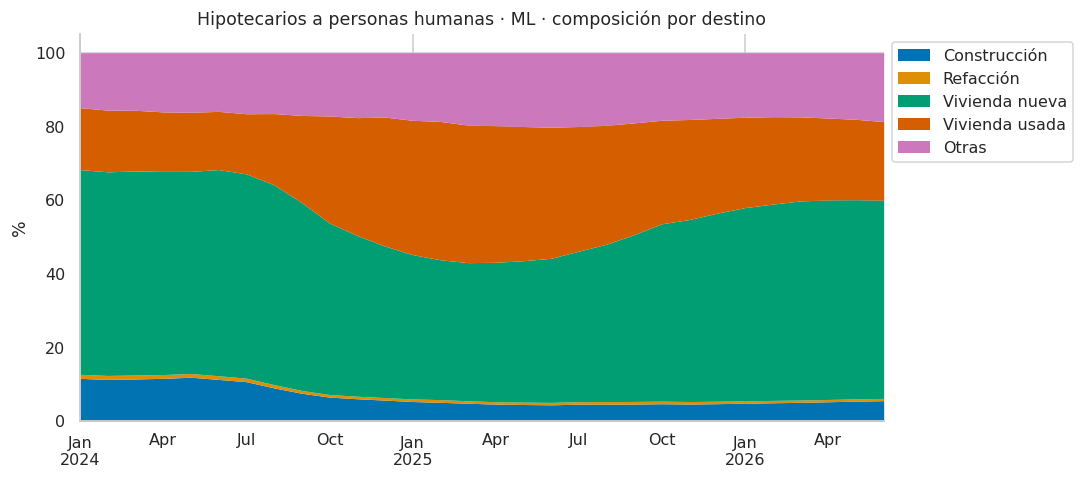

,fecha,Construcción,Refacción,Vivienda nueva,Vivienda usada,Otras
0,2024-01-31,"30,025.000","2,836.000","143,917.000","43,538.000","38,634.000"
1,2024-02-29,"29,372.000","2,823.000","143,602.000","43,525.000","40,491.000"
2,2024-03-31,"29,500.000","2,788.000","142,947.000","42,496.000","40,328.000"
3,2024-04-30,"30,067.000","2,648.000","142,780.000","41,834.000","41,608.000"
4,2024-05-31,"31,000.000","2,622.000","142,938.000","41,794.000","42,091.000"
5,2024-06-30,"30,378.000","2,696.000","150,369.000","42,432.000","42,802.000"
6,2024-07-31,"31,681.000","2,828.000","164,279.000","48,356.000","49,083.000"
7,2024-08-31,"33,919.000","3,335.000","204,306.000","72,873.000","62,258.000"
8,2024-09-30,"38,536.000","3,873.000","260,147.000","120,906.000","86,884.000"
9,2024-10-31,"48,232.000","5,184.000","344,621.000","215,159.000","127,218.000"


En el último mes, el principal destino entre estas aperturas es **Vivienda nueva** (53.8%).

In [5]:
line_groups = {
    'Hipotecarios · ML': [927,929,935,936], 'Hipotecarios · ME': [938,940,946,947],
    'Prendarios · ML': [960,962,968,969], 'Prendarios · ME': [971,973,979,980]}
segment_names = list(eda.SEGMENTS.values())
fig, axes = plt.subplots(2,2, figsize=(13,8))
for ax, (title, ids) in zip(axes.flat, line_groups.items()):
    frame = aw[ids].loc[RECENT_START:].dropna(how='all').rename(columns=dict(zip(ids,segment_names)))
    (frame/1e6).plot(ax=ax, linewidth=1.8)
    ax.set(title=title, ylabel='Millones de unidades publicadas', xlabel='')
    ax.legend(fontsize=8)
figsave(fig,'A3_lineas_moneda_titular')
dest = aw[[1145,1146,1147,1148,1149]].loc[RECENT_START:].dropna(how='all')
dest.columns=['Construcción','Refacción','Vivienda nueva','Vivienda usada','Otras']
fig, ax = plt.subplots(figsize=(10,4.5))
(dest.div(dest.sum(axis=1,min_count=5),axis=0)*100).plot.area(ax=ax, linewidth=0)
ax.set(title='Hipotecarios a personas humanas · ML · composición por destino',ylabel='%',xlabel='')
ax.legend(loc='upper left',bbox_to_anchor=(1,1)); figsave(fig,'A4_destinos_hipotecarios')
table(dest.reset_index(names='fecha'), 'A4_destinos_hipotecarios')
say(f'En el último mes, el principal destino entre estas aperturas es **{dest.iloc[-1].idxmax()}** '
    f'({100*dest.iloc[-1].max()/dest.iloc[-1].sum():.1f}%).')

## A3. ¿Cómo evolucionaron las tasas y qué distingue al período reciente?

Se muestran familias de tasas con significado compatible. La tasa sobre UVA tiene un panel propio. Las medias mensuales de series diarias son resúmenes descriptivos de las fechas observadas; el último mes diario está abierto. La serie 1215 conserva su hueco y la 1199 excluye analíticamente los ceros previos a junio de 1993. El cambio metodológico de TAMAR en 2026 documentado en QA limita su comparación histórica.

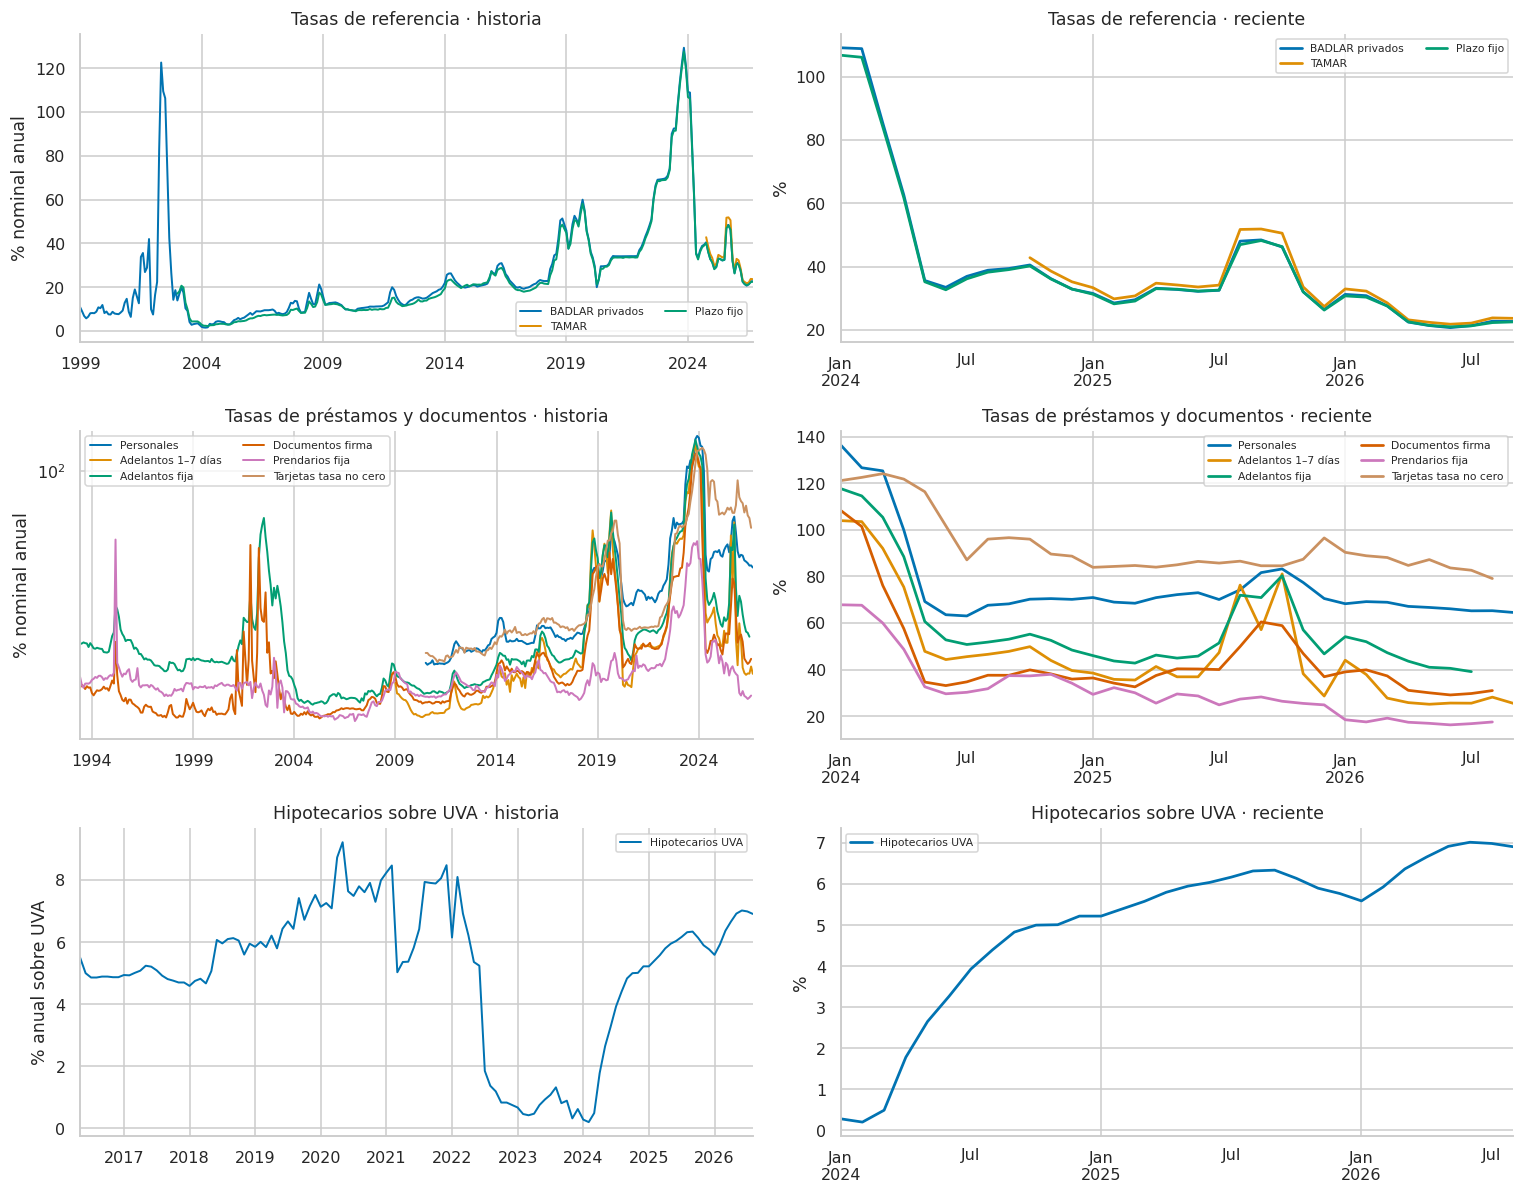

,serie_id,tasa,fecha,valor_ultimo,mediana_historica,percentil_empirico_ultimo
0,7,BADLAR privados,2026-09-10,22.312,19.562,61.128
1,14,Personales,2026-09-10,63.460,47.325,68.274
2,135,TAMAR,2026-09-10,23.000,32.812,17.094
3,145,Adelantos 1–7 días,2026-09-10,25.440,27.640,41.318
4,1189,Plazo fijo,2026-09-10,22.220,19.130,60.806
5,1199,Adelantos fija,2026-07-31,39.190,31.035,68.593
6,1215,Tarjetas (total),2026-08-31,79.110,40.880,83.271
7,1216,Documentos firma,2026-08-31,31.070,20.600,72.682
8,1218,Prendarios fija,2026-08-31,17.610,21.580,22.055
9,1220,Tarjetas tasa no cero,2026-08-31,79.110,42.995,76.804


,idVariable,mes,valor_eda,n_observaciones,ultima_observacion,serie_id,frecuencia,tipo_valor,mes_diario_abierto,fecha
332,7,2026-09,22.641,8,2026-09-10,7,D,tasa_nominal_anual,True,2026-09-30
527,14,2026-09,64.565,8,2026-09-10,14,D,tasa_nominal_anual,True,2026-09-30
2545,135,2026-09,23.633,8,2026-09-10,135,D,tasa_nominal_anual,True,2026-09-30
2758,145,2026-09,25.590,8,2026-09-10,145,D,tasa_nominal_anual,True,2026-09-30
19631,1189,2026-09,22.504,8,2026-09-10,1189,D,tasa_nominal_anual,True,2026-09-30


In [6]:
rate_groups = {'Tasas de referencia': [7,135,1189],
               'Tasas de préstamos y documentos':[14,145,1199,1216,1218,1220],
               'Hipotecarios sobre UVA':[1240]}
fig, axes = plt.subplots(3,2, figsize=(14,11))
for row,(title,ids) in enumerate(rate_groups.items()):
    data=aw[ids].dropna(how='all').rename(columns=eda.RATE_LABELS)
    data=data.reindex(pd.date_range(data.index.min(),data.index.max(),freq='ME'))
    data.plot(ax=axes[row,0],linewidth=1.3)
    data.loc[RECENT_START:].plot(ax=axes[row,1],linewidth=1.8)
    axes[row,0].set(title=title+' · historia',xlabel='',ylabel='% nominal anual' if row<2 else '% anual sobre UVA')
    axes[row,1].set(title=title+' · reciente',xlabel='',ylabel='%')
    if row==1: axes[row,0].set_yscale('symlog',linthresh=100)
    for ax in axes[row]:ax.legend(fontsize=7,ncol=2)
figsave(fig,'A5_tasas_historia_reciente')
rates_last=[]
for i,label in eda.RATE_LABELS.items():
    s=a[a.idVariable.eq(i)].dropna(subset=['valor_eda']).sort_values('fecha')
    rates_last.append({'serie_id':i,'tasa':label,'fecha':s.fecha.iloc[-1],
                       'valor_ultimo':s.valor_eda.iloc[-1],
                       'mediana_historica':s.valor_eda.median(),
                       'percentil_empirico_ultimo':100*s.valor_eda.le(s.valor_eda.iloc[-1]).mean()})
table(pd.DataFrame(rates_last),'A5_tasas_ultimo',rows=15)
table(a_monthly[a_monthly.mes_diario_abierto], 'A5_meses_diarios_abiertos')

## A4. ¿Qué asociaciones descriptivas aparecen entre tasas, crédito e inflación?

Para evitar correlacionar directamente niveles nominales tendenciales, el gráfico compara variaciones mensuales de stocks, cambios de tasas en puntos porcentuales e inflación mensual, desde 2024. Se usan meses calendario consecutivos; no se rellenan huecos. La matriz utiliza la intersección común completa y excluye el mes diario abierto. Se informa n; no se calculan pruebas de causalidad ni significancia bajo independencia temporal.

No se evalúa la relación con depósitos, agregados monetarios ni evolución cambiaria: esos insumos no están disponibles. El tipo de cambio de una única fecha queda documentado como fotografía.

30 filas en outputs/tablas/A6_interseccion_asociaciones.csv; vista: primeras 16.


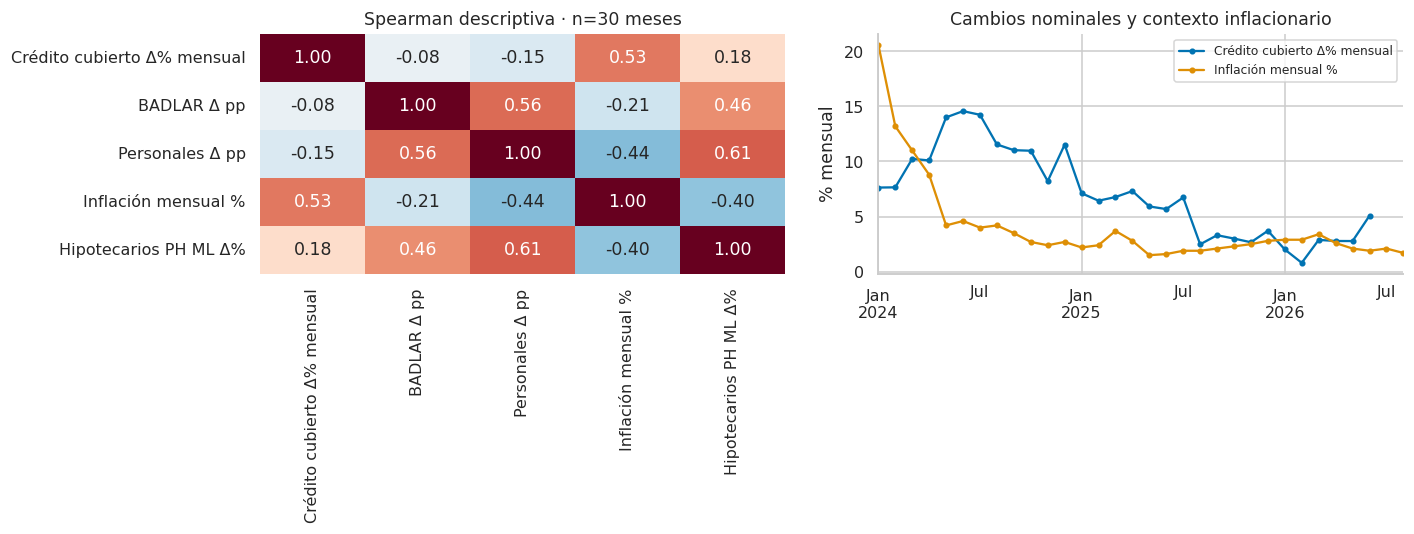

,fecha,Crédito cubierto Δ% mensual,BADLAR Δ pp,Personales Δ pp,Inflación mensual %,Hipotecarios PH ML Δ%
0,2024-01-31,7.636,-12.003,-2.383,20.600,-1.148
1,2024-02-29,7.655,-0.273,-9.749,13.200,0.333
2,2024-03-31,10.240,-23.480,-1.336,11.000,-0.675
3,2024-04-30,10.094,-22.746,-25.336,8.800,0.341
4,2024-05-31,14.004,-27.084,-30.687,4.200,0.582
5,2024-06-30,14.571,-2.159,-5.668,4.600,3.160
6,2024-07-31,14.238,3.480,-0.520,4.000,10.255
7,2024-08-31,11.549,1.938,4.582,4.200,27.163
8,2024-09-30,11.028,0.537,0.604,3.500,35.481
9,2024-10-31,10.977,1.128,2.002,2.700,45.081


,fecha,codigoMoneda,descripcion,tipoPase,tipoCotizacion
0,2026-09-11,USD,DOLAR E.E.U.U.,0.000,"1,508.500"


La intersección para asociaciones contiene **30 meses**. Cambios nominales por encima de inflación en una observación aislada no permiten identificar un régimen ni una causa.

In [7]:
total_calendar=stock_total.reindex(aw.index)
relations=pd.DataFrame(index=aw.index)
relations['Crédito cubierto Δ% mensual']=total_calendar.pct_change(fill_method=None)*100
relations['BADLAR Δ pp']=aw[7].diff()
relations['Personales Δ pp']=aw[14].diff()
relations['Inflación mensual %']=aw[27]
relations['Hipotecarios PH ML Δ%']=aw[927].pct_change(fill_method=None)*100
relations=relations.replace([np.inf,-np.inf],np.nan).loc[RECENT_START:]
open_months=set(a_monthly.loc[a_monthly.mes_diario_abierto,'fecha'])
relations=relations.loc[~relations.index.isin(open_months)]
common=relations.dropna()
corr=common.corr(method='spearman') if len(common)>=6 else pd.DataFrame()
fig,axes=plt.subplots(1,2,figsize=(13,5))
if not corr.empty:
    sns.heatmap(corr,annot=True,fmt='.2f',vmin=-1,vmax=1,cmap='RdBu_r',ax=axes[0],cbar=False)
    axes[0].set_title(f'Spearman descriptiva · n={len(common)} meses')
relations[['Crédito cubierto Δ% mensual','Inflación mensual %']].plot(ax=axes[1],marker='o',markersize=3)
axes[1].set(title='Cambios nominales y contexto inflacionario',ylabel='% mensual',xlabel='')
axes[1].legend(fontsize=8)
figsave(fig,'A6_asociaciones_descriptivas')
table(common.reset_index(names='fecha'),'A6_interseccion_asociaciones')
table(fx,'A6_cotizacion_disponible')
say(f'La intersección para asociaciones contiene **{len(common)} meses**. '
    'Cambios nominales por encima de inflación en una observación aislada no permiten identificar un régimen ni una causa.')
eda.save_table(a_monthly.assign(mes=a_monthly.mes.astype(str)), 'A_mensual_descriptivo',OUT)

# B. Estructura de la oferta publicada
## B1. ¿Cuántos registros y entidades se observan, y cómo se distribuyen sus costos?

La fotografía utiliza el último snapshot completo, común a las cuatro familias. Un registro no identifica necesariamente una oferta única: las claves de variantes siguen siendo ambiguas. Las cantidades de entidades y registros describen cobertura publicada, sin ponderación por volumen de crédito, clientes ni cuota de mercado.

Las distribuciones comparables se separan por denominación y tipo de tasa. Para tarjetas, esos atributos no están publicados en el esquema y se mantienen como no informados. Las tasas son **máximas informadas**, no tasas efectivamente contratadas. Los cuadros exportados conservan n, p25, mediana, p75, p95, mínimo y máximo.

261 filas en outputs/tablas/B_agregados_snapshot_estrato.csv; vista: primeras 8.


,snapshot_date,snapshot_id,family,denominacion_eda,tipo_tasa_eda,n_registros,n_entidades,n_familias_logicas,n_fecha_informacion_desconocida,...,ingreso_min_n,ingreso_min_p25,ingreso_min_mediana,ingreso_min_p75,ingreso_min_p95,ingreso_min_min,ingreso_min_max,ingreso_min_mediana_entidades,ingreso_min_n_entidades_validas
0,2026-09-07,20260907_212935_569641,hipotecarios,No informada,No informado,1,1,1,0,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,2026-09-07,20260907_212935_569641,hipotecarios,Pesos,Fija,2,2,2,0,...,2,"8,750.000","17,500.000","26,250.000","33,250.000",0.000,"35,000.000","17,500.000",2
2,2026-09-07,20260907_212935_569641,hipotecarios,Pesos,Variable,85,3,85,0,...,85,0.000,0.000,"3,500,000.000","3,500,000.000",0.000,"3,500,000.000",0.000,3
3,2026-09-07,20260907_212935_569641,hipotecarios,USD,Fija,6,1,6,0,...,6,"63,750.000","90,000.000","90,000.000","90,000.000","55,000.000","90,000.000","90,000.000",1
4,2026-09-07,20260907_212935_569641,hipotecarios,UVA,Fija,175,26,152,0,...,175,"735,600.000","850,000.000","1,506,400.000","5,150,000.000",0.000,"10,000,000.000","924,999.500",26
5,2026-09-07,20260907_212935_569641,hipotecarios,UVA,Mixta,1,1,1,0,...,1,"1,000,000.000","1,000,000.000","1,000,000.000","1,000,000.000","1,000,000.000","1,000,000.000","1,000,000.000",1
6,2026-09-07,20260907_212935_569641,personales,No informada,Fija,5,1,5,0,...,5,"780,000.000","780,000.000","780,000.000","780,000.000","780,000.000","780,000.000","780,000.000",1
7,2026-09-07,20260907_212935_569641,personales,No informada,No informado,3,3,3,0,...,1,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1


,family,registros,entidades,tea_n,cftea_n
0,hipotecarios,272,30,271,271
1,personales,2291,291,2289,2289
2,prendarios,492,49,491,491
3,tarjetas,537,137,535,0


**Fotografía:** 2026-09-23, snapshot `20260923_184541_323882`; 3,592 registros. Las 367 entidades distintas no deben sumarse entre familias.

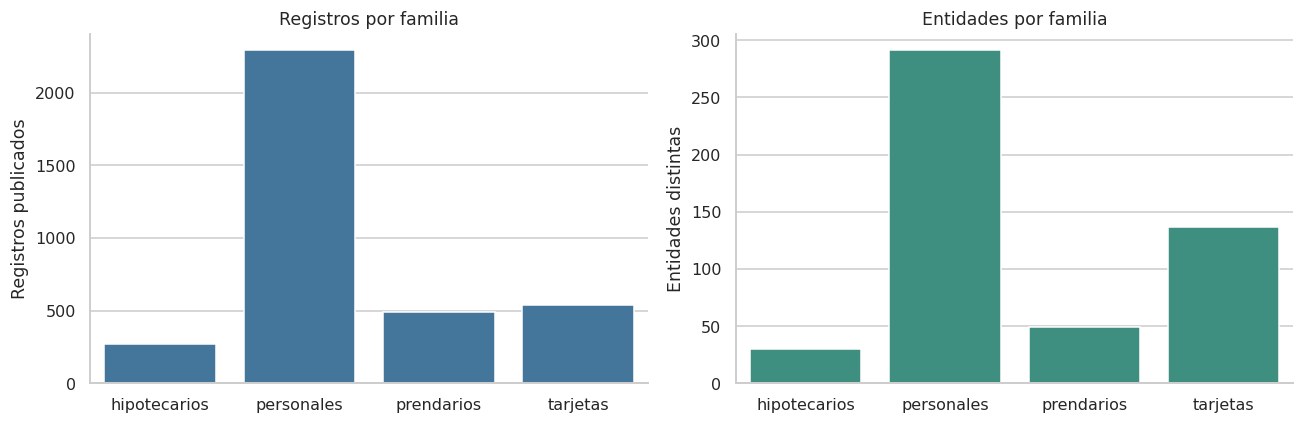

In [8]:
b_stats=eda.summarize_b(b)
b_entity_stats=eda.summarize_b(b,by_entity=True)
b_fresh_stats=eda.summarize_b(b,freshness=True)
table(b_stats,'B_agregados_snapshot_estrato',rows=8)
eda.save_table(b_entity_stats,'B_agregados_snapshot_entidad_estrato',OUT)
eda.save_table(b_fresh_stats,'B_sensibilidad_hasta_365_dias',OUT)
eda.save_table(b_exclusions,'B_valores_no_interpretables',OUT)
b_cover=bl.groupby('family').agg(registros=('family','size'),entidades=('codigoEntidad','nunique'),
                                 tea_n=('tea','count'),cftea_n=('cftea','count')).reset_index()
table(b_cover,'B1_cobertura_ultimo',rows=8)
say(f'**Fotografía:** {bl.snapshot_date.max():%Y-%m-%d}, snapshot `{latest_sid}`; '
    f'{len(bl):,} registros. Las {bl.codigoEntidad.nunique()} entidades distintas no deben sumarse entre familias.')
fig,axes=plt.subplots(1,2,figsize=(12,4))
sns.barplot(data=b_cover,x='family',y='registros',ax=axes[0],color='#3579a8')
sns.barplot(data=b_cover,x='family',y='entidades',ax=axes[1],color='#309c87')
axes[0].set(title='Registros por familia',xlabel='',ylabel='Registros publicados')
axes[1].set(title='Entidades por familia',xlabel='',ylabel='Entidades distintas')
figsave(fig,'B1_cobertura')

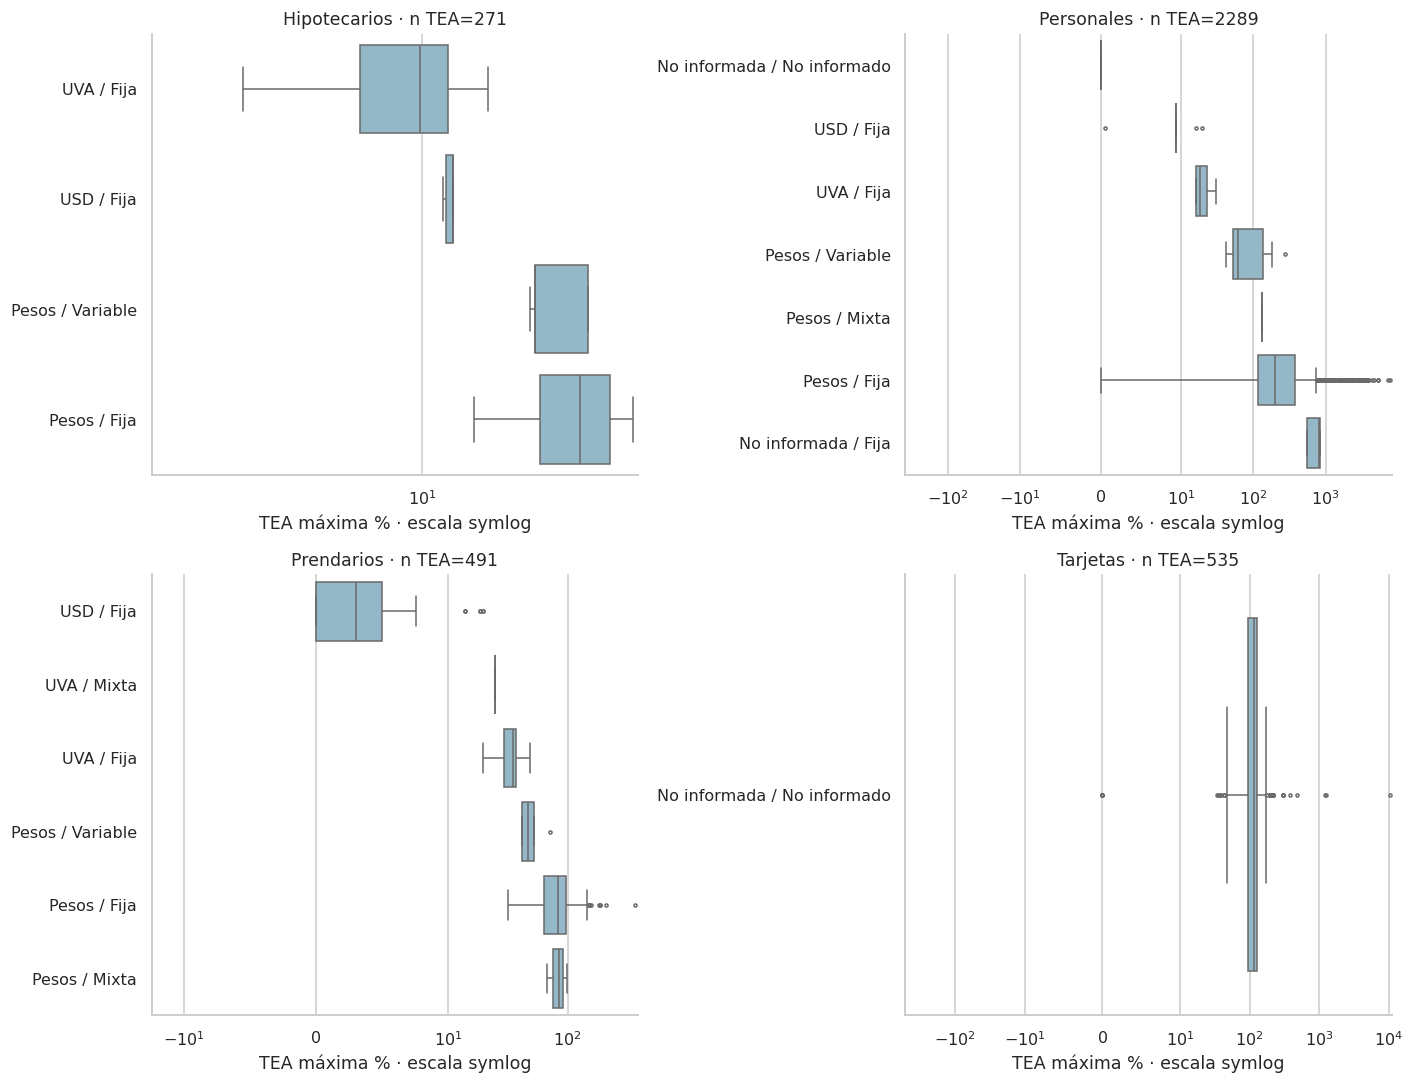

,family,denominacion_eda,tipo_tasa_eda,n_registros,n_entidades,tea_n,tea_mediana,tea_p25,tea_p75,cftea_n,cftea_mediana
241,hipotecarios,No informada,No informado,1,1,0,NaN,NaN,NaN,0,NaN
242,hipotecarios,Pesos,Fija,2,2,2,42.845,29.473,56.218,2,43.505
243,hipotecarios,Pesos,Variable,85,3,85,28.190,28.190,45.950,85,28.280
244,hipotecarios,USD,Fija,6,1,6,13.240,12.408,13.240,6,16.450
245,hipotecarios,UVA,Fija,178,26,178,9.920,7.760,12.690,178,10.460
246,personales,No informada,Fija,5,1,5,814.280,558.040,837.270,5,943.170
247,personales,No informada,No informado,3,3,1,0.000,0.000,0.000,1,0.000
248,personales,Pesos,Fija,2246,286,2246,201.770,117.020,370.420,2246,239.080
249,personales,Pesos,Mixta,3,1,3,133.000,133.000,133.000,3,173.000
250,personales,Pesos,Variable,17,6,17,61.430,51.760,135.000,17,65.360


La escala symlog mantiene visibles los ceros y las colas extremas. La amplitud entre estratos incluye diferencias de indexación, moneda y modalidad; no representa un ranking de conveniencia.

In [9]:
bl['estrato']=bl.denominacion_eda+' / '+bl.tipo_tasa_eda
fig,axes=plt.subplots(2,2,figsize=(13,10))
for ax,fam in zip(axes.flat,eda.FAMILIES):
    g=bl[bl.family.eq(fam)].dropna(subset=['tea'])
    order=g.groupby('estrato').tea.median().sort_values().index
    sns.boxplot(data=g,x='tea',y='estrato',order=order,ax=ax,color='#8dbbd0',fliersize=2)
    ax.set_xscale('symlog',linthresh=10)
    ax.set(title=f'{fam.title()} · n TEA={len(g)}',xlabel='TEA máxima % · escala symlog',ylabel='')
figsave(fig,'B2_tea_por_estrato')
latest_stats=b_stats[b_stats.snapshot_id.eq(latest_sid)]
cols=['family','denominacion_eda','tipo_tasa_eda','n_registros','n_entidades','tea_n','tea_mediana','tea_p25','tea_p75','cftea_n','cftea_mediana']
table(latest_stats[cols],'B2_distribuciones_ultimo',rows=24)
say('La escala symlog mantiene visibles los ceros y las colas extremas. '
    'La amplitud entre estratos incluye diferencias de indexación, moneda y modalidad; no representa un ranking de conveniencia.')

## B2. ¿Cuánta dispersión existe entre entidades y cuánto depende de la composición?

Se utiliza el estrato personales / pesos / tasa fija como ejemplo amplio. Cada entidad se resume por la mediana de sus registros. El gráfico muestra diez entidades con las medianas más bajas y diez con las más altas dentro de este estrato; incluye el número de registros válidos. Es una posición descriptiva: plazos, montos, beneficiarios y demás condiciones aún difieren.

La tabla contrasta la mediana de todos los registros con la mediana de las medianas por entidad. La segunda asigna igual peso a cada entidad con dato disponible. Ninguna representa una tasa promedio del crédito efectivamente otorgado.

286 filas en outputs/tablas/B3_posicion_entidades_personales_pesos_fija.csv; vista: primeras 12.


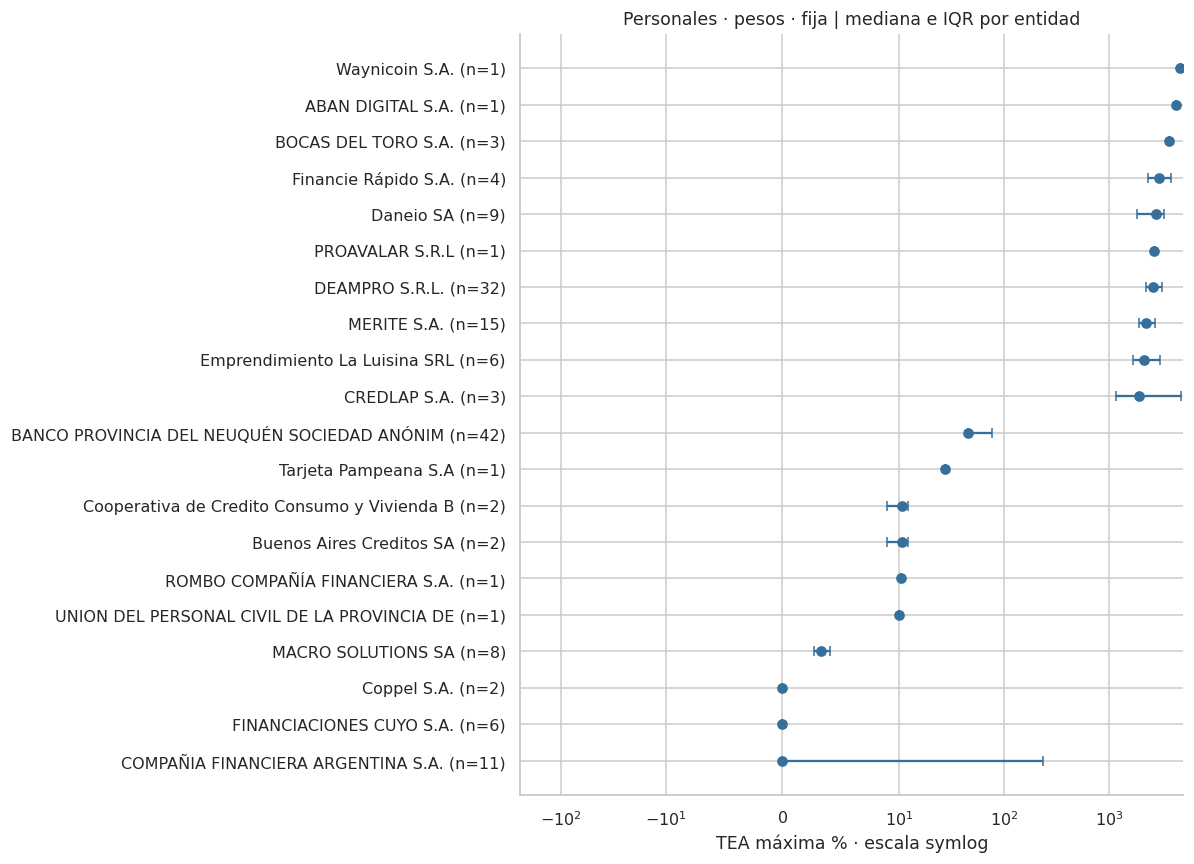

,codigoEntidad,descripcionEntidad,tea_n,tea_mediana,tea_p25,tea_p75
6548,44077,COMPAÑIA FINANCIERA ARGENTINA S.A.,11,0.000,0.000,235.805
6605,55096,FINANCIACIONES CUYO S.A.,6,0.000,0.000,0.000
6567,55015,Coppel S.A.,2,0.000,0.000,0.000
6671,55310,MACRO SOLUTIONS SA,8,3.335,2.708,4.062
6680,55331,UNION DEL PERSONAL CIVIL DE LA PROVINCIA DEL C...,1,10.000,10.000,10.000
6550,44095,ROMBO COMPAÑÍA FINANCIERA S.A.,1,10.360,10.360,10.360
6667,55300,Buenos Aires Creditos SA,2,10.550,8.940,12.160
6722,55453,Cooperativa de Credito Consumo y Vivienda Baym...,2,10.550,8.940,12.160
6767,70301,Tarjeta Pampeana S.A,1,27.230,27.230,27.230
6797,97,BANCO PROVINCIA DEL NEUQUÉN SOCIEDAD ANÓNIMA,42,45.380,45.380,76.230


,family,denominacion_eda,tipo_tasa_eda,tea_n,tea_mediana,tea_mediana_entidades,tea_n_entidades_validas
241,hipotecarios,No informada,No informado,0,NaN,NaN,0
242,hipotecarios,Pesos,Fija,2,42.845,42.845,2
243,hipotecarios,Pesos,Variable,85,28.190,41.250,3
244,hipotecarios,USD,Fija,6,13.240,13.240,1
245,hipotecarios,UVA,Fija,178,9.920,9.850,26
246,personales,No informada,Fija,5,814.280,814.280,1
247,personales,No informada,No informado,1,0.000,0.000,1
248,personales,Pesos,Fija,2246,201.770,218.205,286
249,personales,Pesos,Mixta,3,133.000,133.000,1
250,personales,Pesos,Variable,17,61.430,77.490,6


,family,denominacion_eda,tipo_tasa_eda,tea_n_todo,tea_n_hasta365,tea_mediana_todo,tea_mediana_hasta365
0,hipotecarios,No informada,No informado,0,NaN,NaN,NaN
1,hipotecarios,Pesos,Fija,2,2.000,42.845,42.845
2,hipotecarios,Pesos,Variable,85,85.000,28.190,28.190
3,hipotecarios,USD,Fija,6,6.000,13.240,13.240
4,hipotecarios,UVA,Fija,178,178.000,9.920,9.920
5,personales,No informada,Fija,5,5.000,814.280,814.280
6,personales,No informada,No informado,1,0.000,0.000,NaN
7,personales,Pesos,Fija,2246,"1,920.000",201.770,181.270
8,personales,Pesos,Mixta,3,3.000,133.000,133.000
9,personales,Pesos,Variable,17,16.000,61.430,61.430


In [10]:
ent=b_entity_stats[(b_entity_stats.snapshot_id.eq(latest_sid)) &
    b_entity_stats.family.eq('personales') & b_entity_stats.denominacion_eda.eq('Pesos') &
    b_entity_stats.tipo_tasa_eda.eq('Fija')].dropna(subset=['tea_mediana']).sort_values('tea_mediana')
selected=pd.concat([ent.head(10),ent.tail(10)]).drop_duplicates('codigoEntidad')
selected=selected.sort_values('tea_mediana').copy()
selected['etiqueta']=selected.descripcionEntidad.str.slice(0,43)+' (n='+selected.tea_n.astype(int).astype(str)+')'
fig,ax=plt.subplots(figsize=(11,8))
ax.errorbar(selected.tea_mediana,np.arange(len(selected)),
            xerr=[selected.tea_mediana-selected.tea_p25,selected.tea_p75-selected.tea_mediana],
            fmt='o',color='#356f9c',capsize=3)
ax.set_yticks(np.arange(len(selected)),selected.etiqueta)
ax.set_xscale('symlog',linthresh=10)
ax.set(title='Personales · pesos · fija | mediana e IQR por entidad',xlabel='TEA máxima % · escala symlog')
figsave(fig,'B3_dispersion_entidades')
table(ent[['codigoEntidad','descripcionEntidad','tea_n','tea_mediana','tea_p25','tea_p75']],
      'B3_posicion_entidades_personales_pesos_fija',rows=12)
weighting=latest_stats[['family','denominacion_eda','tipo_tasa_eda','tea_n','tea_mediana','tea_mediana_entidades','tea_n_entidades_validas']]
table(weighting,'B3_sensibilidad_ponderacion',rows=24)
keys=['snapshot_id','family','denominacion_eda','tipo_tasa_eda']
fresh_compare=latest_stats.merge(b_fresh_stats[b_fresh_stats.snapshot_id.eq(latest_sid)][keys+['tea_n','tea_mediana']],
                               on=keys,how='left',suffixes=('_todo','_hasta365'),validate='one_to_one')
table(fresh_compare[['family','denominacion_eda','tipo_tasa_eda','tea_n_todo','tea_n_hasta365','tea_mediana_todo','tea_mediana_hasta365']],
      'B3_sensibilidad_antiguedad',rows=24)

## B3. ¿Cómo se relacionan costo, plazo, monto e ingreso? ¿Qué particularidad tienen los hipotecarios?

El análisis por pares se restringe a personales en pesos a tasa fija. Los montos e ingresos usan las unidades publicadas en ese estrato; ceros se mantienen y se usa escala symlog cuando corresponde. Se informa n de pares completos. Las asociaciones pueden reflejar composición por entidad o requisitos, sin interpretar dirección causal.

Para hipotecarios se resumen por separado denominación y tipo de tasa. En UVA, la cuota y el capital se encuentran vinculados a la unidad publicada; comparar sólo la TEA con pesos omite esa diferencia. Se muestran las relaciones cuota/ingreso y monto/tasación de la capa normalizada recibida, sin reinterpretar sus unidades originales.

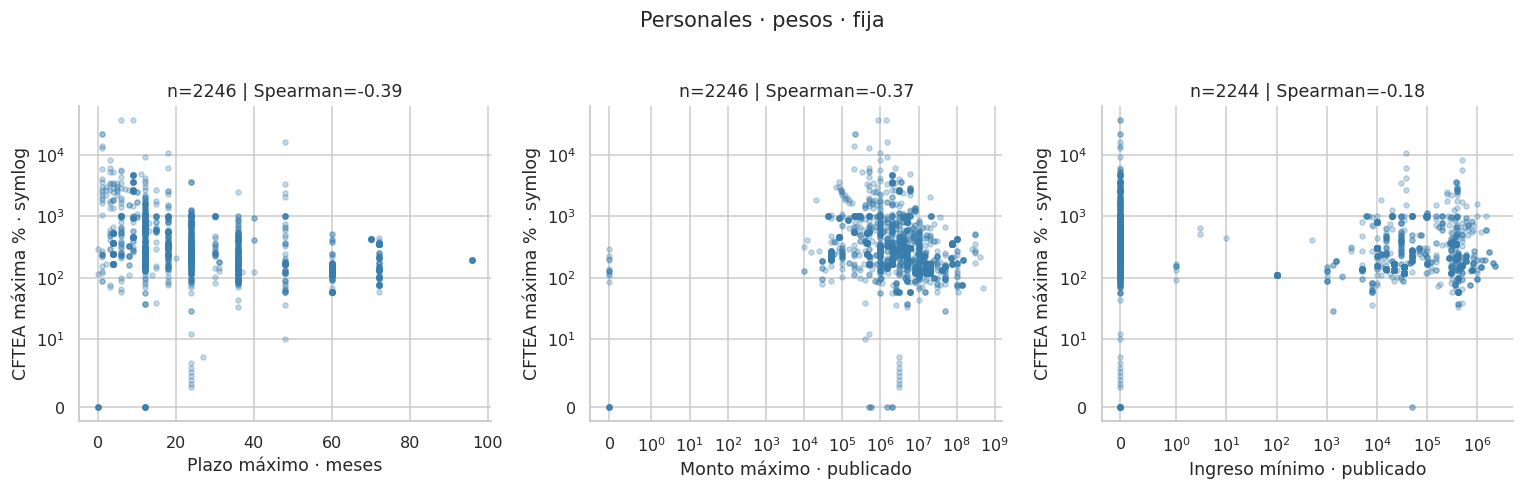

,x,y,n,spearman
0,plazo_meses,cftea,2246,-0.385
1,monto_max,cftea,2246,-0.370
2,ingreso_min,cftea,2244,-0.177


,denominacion_eda,tipo_tasa_eda,n,entidades,tea_n,tea_mediana,cftea_n,cftea_mediana,plazo_n,plazo_mediana,cuota_ingreso_n,cuota_ingreso_mediana,monto_tasacion_n,monto_tasacion_mediana
0,No informada,No informado,1,1,0,NaN,0,NaN,0,NaN,0,NaN,0,NaN
1,Pesos,Fija,2,2,2,42.845,2,43.505,2,84.000,2,30.000,2,42.500
2,Pesos,Variable,85,3,85,28.190,85,28.280,85,180.000,85,40.000,85,70.000
3,USD,Fija,6,1,6,13.240,6,16.450,6,60.000,6,50.000,6,50.000
4,UVA,Fija,178,26,178,9.920,178,10.460,178,240.000,178,25.000,178,75.000


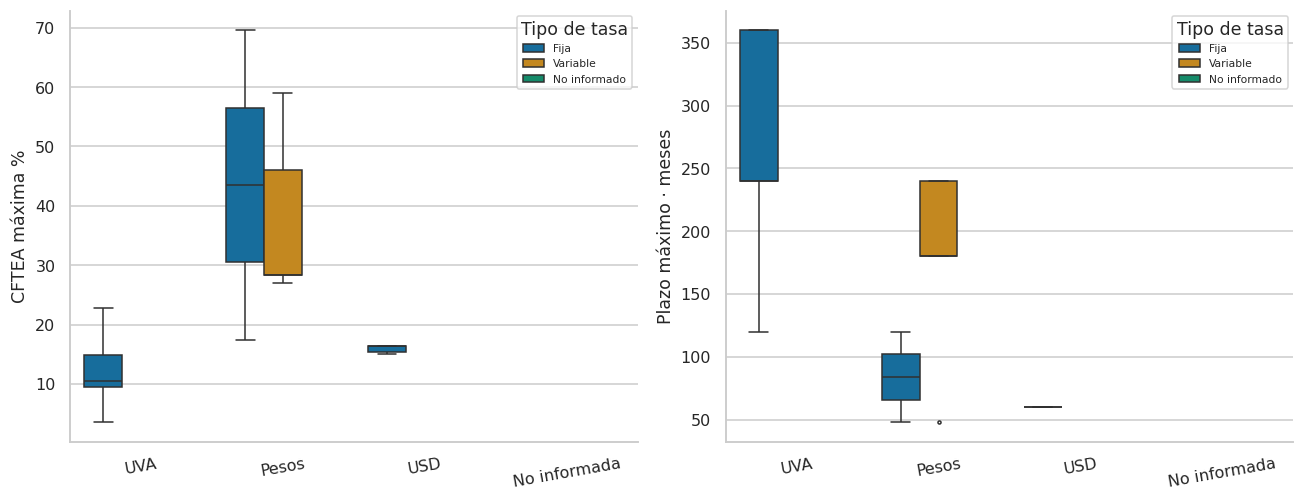

In [11]:
bp=bl[bl.family.eq('personales') & bl.denominacion_eda.eq('Pesos') & bl.tipo_tasa_eda.eq('Fija')]
fig,axes=plt.subplots(1,3,figsize=(14,4.3))
pair_results=[]
for ax,(x,label) in zip(axes,[('plazo_meses','Plazo máximo · meses'),('monto_max','Monto máximo · publicado'),('ingreso_min','Ingreso mínimo · publicado')]):
    g=bp[[x,'cftea']].dropna()
    ax.scatter(g[x],g.cftea,s=11,alpha=.28,color='#387dac')
    if x!='plazo_meses':ax.set_xscale('symlog',linthresh=1)
    ax.set_yscale('symlog',linthresh=10)
    rho=g.corr(method='spearman').loc[x,'cftea'] if len(g)>2 else np.nan
    ax.set(title=f'n={len(g)} | Spearman={rho:.2f}',xlabel=label,ylabel='CFTEA máxima % · symlog')
    pair_results.append({'x':x,'y':'cftea','n':len(g),'spearman':rho})
fig.suptitle('Personales · pesos · fija',y=1.03)
figsave(fig,'B4_requisitos_costo')
table(pd.DataFrame(pair_results),'B4_asociaciones_pares')
bh=bl[bl.family.eq('hipotecarios')]
hsummary=bh.groupby(['denominacion_eda','tipo_tasa_eda'],dropna=False).agg(
    n=('family','size'),entidades=('codigoEntidad','nunique'),tea_n=('tea','count'),tea_mediana=('tea','median'),
    cftea_n=('cftea','count'),cftea_mediana=('cftea','median'),plazo_n=('plazo_meses','count'),plazo_mediana=('plazo_meses','median'),
    cuota_ingreso_n=('relacionCuotaIngreso_pct','count'),cuota_ingreso_mediana=('relacionCuotaIngreso_pct','median'),
    monto_tasacion_n=('relacionMontoTasacion_pct','count'),monto_tasacion_mediana=('relacionMontoTasacion_pct','median')).reset_index()
table(hsummary,'B4_hipotecarios',rows=12)
fig,axes=plt.subplots(1,2,figsize=(12,4.7))
for ax,y,label in zip(axes,['cftea','plazo_meses'],['CFTEA máxima %','Plazo máximo · meses']):
    sns.boxplot(data=bh,x='denominacion_eda',y=y,hue='tipo_tasa_eda',ax=ax,fliersize=2)
    ax.set(xlabel='',ylabel=label);ax.tick_params(axis='x',rotation=10)
    ax.legend(fontsize=7,title='Tipo de tasa')
figsave(fig,'B5_hipotecarios')

## B4. ¿Cómo cambian las distribuciones entre snapshots?

Se elige el último snapshot completo de cada día. Se conservan todos en las tablas exportadas; el inventario informa cuál se usa para la curva. Los días sin captura quedan vacíos. La ventana disponible es corta: cambios de la mediana pueden deberse a mezcla de registros, entidades, condiciones o actualizaciones. No se interpretan como altas/bajas de una oferta individual ni como cambios de tasa de un producto constante.

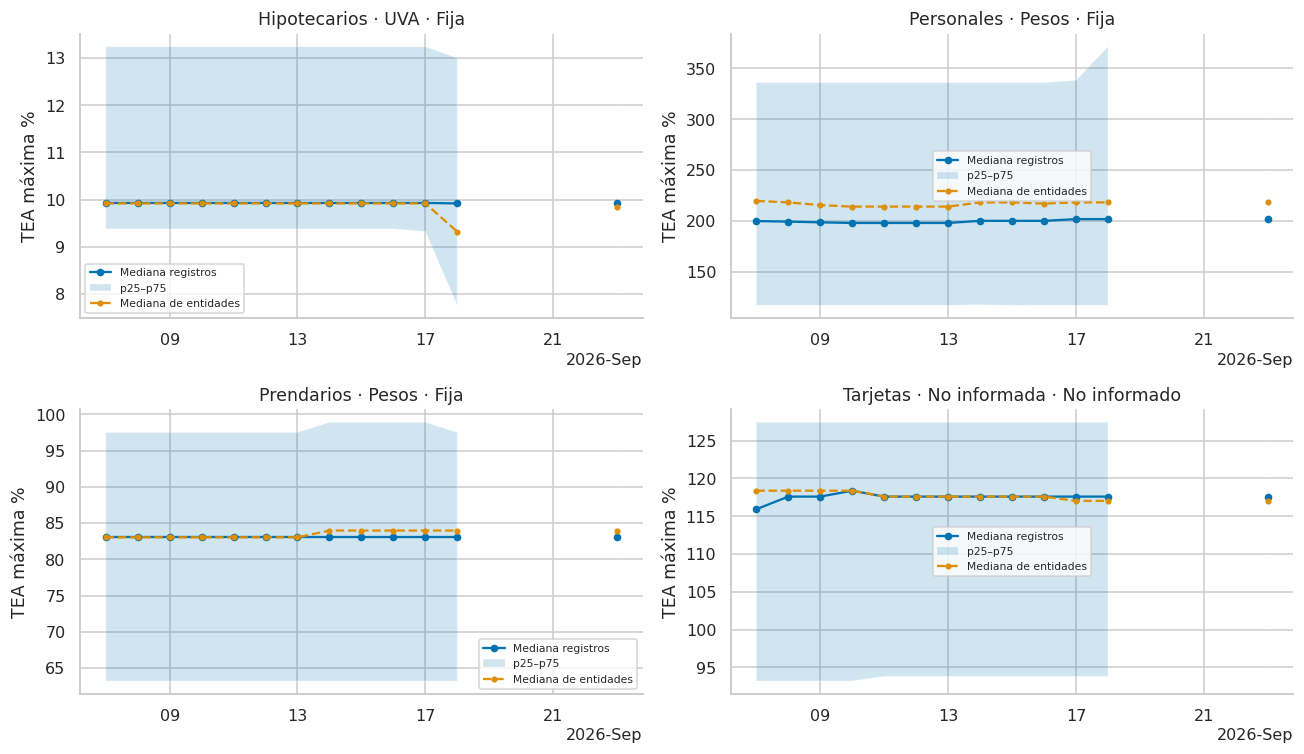

,family,denominacion,tipo_tasa,desde,hasta,n_inicial,n_final,delta_mediana_tea_pp
0,hipotecarios,UVA,Fija,2026-09-07,2026-09-23,175,178,-0.010
1,personales,Pesos,Fija,2026-09-07,2026-09-23,2238,2246,1.900
2,prendarios,Pesos,Fija,2026-09-07,2026-09-23,285,286,0.000
3,tarjetas,No informada,No informado,2026-09-07,2026-09-23,541,537,1.670


In [12]:
daily_stats=b_stats[b_stats.snapshot_id.isin(bd.snapshot_id.unique())]
plots=[('hipotecarios','UVA','Fija'),('personales','Pesos','Fija'),('prendarios','Pesos','Fija'),('tarjetas','No informada','No informado')]
fig,axes=plt.subplots(2,2,figsize=(12,7))
changes=[]
for ax,(fam,den,typ) in zip(axes.flat,plots):
    g=daily_stats[daily_stats.family.eq(fam)&daily_stats.denominacion_eda.eq(den)&daily_stats.tipo_tasa_eda.eq(typ)].sort_values('snapshot_date')
    if len(g)==0:continue
    indexed=g.set_index('snapshot_date').reindex(pd.date_range(bd.snapshot_date.min(),bd.snapshot_date.max(),freq='D'))
    ax.plot(indexed.index,indexed.tea_mediana,marker='o',markersize=4,label='Mediana registros')
    ax.fill_between(indexed.index,indexed.tea_p25,indexed.tea_p75,alpha=.18,label='p25–p75')
    ax.plot(indexed.index,indexed.tea_mediana_entidades,ls='--',marker='.',label='Mediana de entidades')
    ax.set(title=f'{fam.title()} · {den} · {typ}',ylabel='TEA máxima %')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'));ax.legend(fontsize=7)
    changes.append({'family':fam,'denominacion':den,'tipo_tasa':typ,'desde':g.snapshot_date.iloc[0],
                    'hasta':g.snapshot_date.iloc[-1],'n_inicial':g.n_registros.iloc[0],'n_final':g.n_registros.iloc[-1],
                    'delta_mediana_tea_pp':g.tea_mediana.iloc[-1]-g.tea_mediana.iloc[0]})
figsave(fig,'B6_evolucion_agregada')
table(pd.DataFrame(changes),'B6_cambios_agregados')

# C. Endeudamiento empresarial observado
## C1. ¿Qué proporción del panel tiene saldo positivo y cómo se distribuye la deuda?

Se parte del maestro de CUIT seleccionado independientemente de sus resultados crediticios. El panel analítico conserva el universo completo. Los porcentajes usan empresa-mes observados y declaran su denominador. Los saldos se expresan en miles de pesos nominales; para mostrar totales se convierten a miles de millones de ARS. El saldo no mide tamaño económico, patrimonio ni solvencia.

Las métricas de exposición usan sólo filas con saldo positivo; `n_entidades_reportadas` incluye también las filas con monto cero. La diferencia describe entidades informantes sin exposición positiva reportada, sin atribuirles una relación contractual activa o extinguida.

100 filas en outputs/tablas/C2_saldos_empresas_ultimo.csv; vista: primeras 10.


,fecha,empresas_maestro,empresa_mes_observados,activas,deuda_positiva_miles,mediana_deuda_positiva_miles,mediana_entidades_reportadas,mediana_entidades_saldo_positivo,pct_activas_observadas
0,2024-08-01,100,100,97,"1,754,904,496.000","5,061,467.000",11.000,6.000,97.000
1,2024-09-01,100,100,97,"1,979,142,114.000","6,277,415.000",11.000,7.000,97.000
2,2024-10-01,100,100,96,"2,227,883,589.000","6,738,137.500",11.000,7.000,96.000
3,2024-11-01,100,100,97,"2,507,214,585.000","7,380,780.000",11.000,7.000,97.000
4,2024-12-01,100,100,98,"2,603,329,979.000","7,549,634.500",11.000,7.000,98.000
5,2025-01-01,100,100,97,"2,963,883,194.000","8,312,653.000",11.000,7.000,97.000
6,2025-02-01,100,100,98,"2,925,323,565.000","8,467,704.500",11.000,7.000,98.000
7,2025-03-01,100,100,98,"2,968,107,393.000","8,916,911.000",11.000,7.000,98.000
8,2025-04-01,100,100,98,"2,884,122,330.000","8,116,923.500",11.000,7.000,98.000
9,2025-05-01,100,100,99,"3,019,029,446.000","8,166,406.000",11.000,7.000,99.000


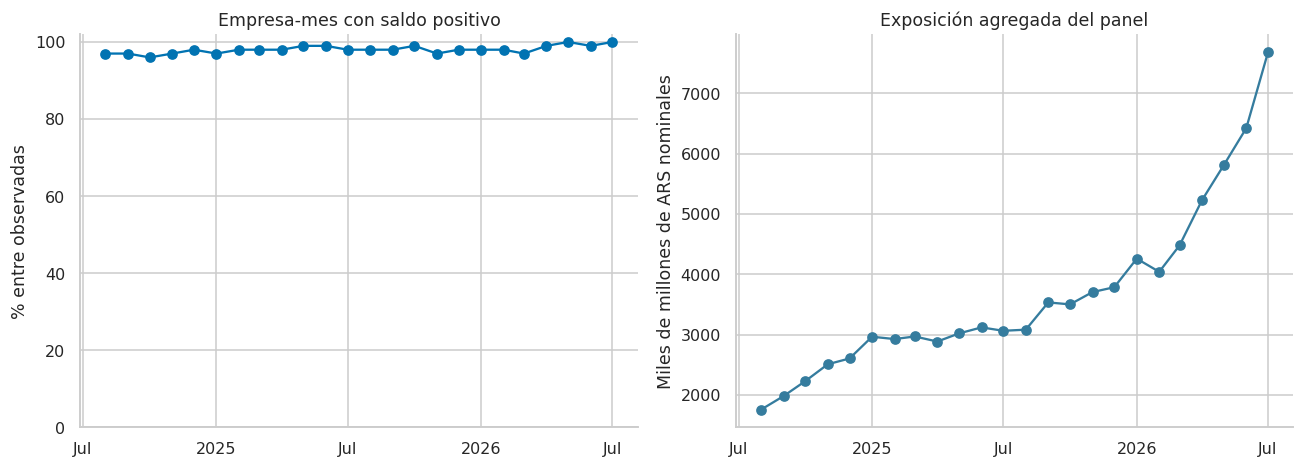

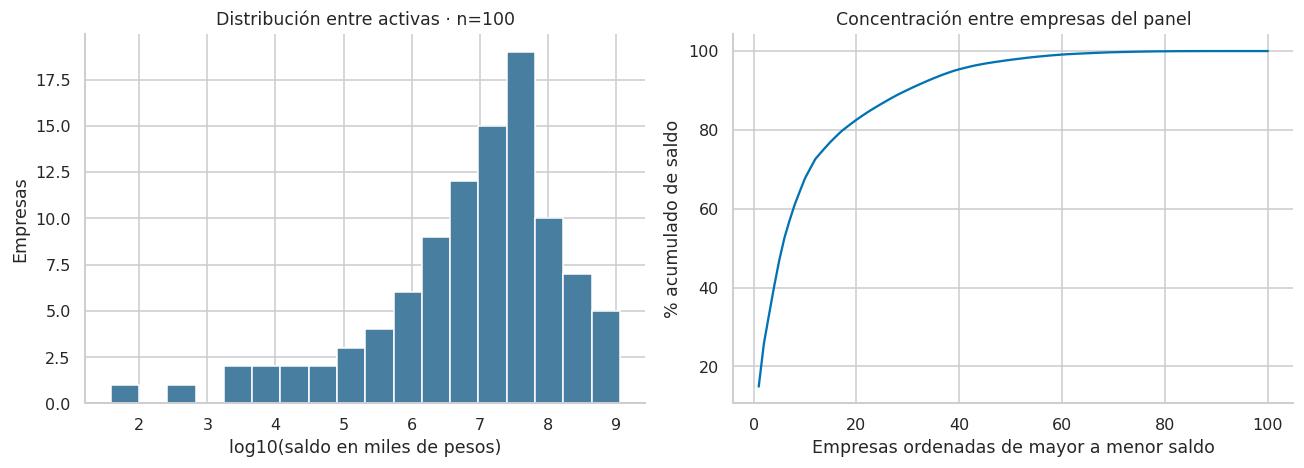

En 2026-07, **100/100** empresas observadas tienen saldo positivo. Las diez de mayor saldo concentran **67.7%** del saldo positivo del panel. Esto describe concentración de deuda observada, no participación sectorial nacional.

,razon_social,cuit_normalizado,deuda_total_positiva,situacion_max_activa
1895,Bunge Argentina S.A.,30700869918,"1,143,765,616.000",1.000
407,Cargill S.A.C.I.,30506792165,"838,181,380.000",5.000
1439,ADM Agro S.R.L.,30621973173,"563,469,858.000",1.000
2255,COFCO International Argentina S.A.,33506737449,"554,705,762.000",1.000
23,Asociación de Cooperativas Argentinas CL,30500120882,"511,507,435.000",1.000
2135,Molinos Agro S.A.,30715118773,"434,330,927.000",1.000
839,Frigorífico Rioplatense S.A.I.C.I.F.,30540080298,"337,882,995.000",1.000
455,MOLINO CAÑUELAS S.A.C.I.F.I.A.,30507950848,"310,144,573.000",5.000
47,Grupo Peñaflor S.A.U.,30500548041,"258,906,174.000",1.000
1391,Adeco Agropecuaria S.A.,30618705672,"252,403,569.000",1.000


In [13]:
eda.save_table(cp,'C_empresa_mes_analitica',OUT)
c_month=cp.groupby('fecha').agg(empresas_maestro=('cuit_normalizado','nunique'),
    empresa_mes_observados=('mes_observado','sum'),activas=('empresa_con_deuda_activa','sum'),
    deuda_positiva_miles=('deuda_total_positiva',lambda s:s.sum(min_count=1)),
    mediana_deuda_positiva_miles=('deuda_total_positiva',lambda s:s[s>0].median()),
    mediana_entidades_reportadas=('n_entidades_reportadas','median'),
    mediana_entidades_saldo_positivo=('n_entidades_con_saldo_positivo','median')).reset_index()
c_month['pct_activas_observadas']=100*c_month.activas/c_month.empresa_mes_observados.replace(0,np.nan)
table(c_month,'C1_evolucion_exposicion',rows=24)
fig,axes=plt.subplots(1,2,figsize=(12,4.4))
axes[0].plot(c_month.fecha,c_month.pct_activas_observadas,marker='o')
axes[0].set(title='Empresa-mes con saldo positivo',ylabel='% entre observadas',ylim=(0,102))
axes[1].plot(c_month.fecha,c_month.deuda_positiva_miles/1e6,marker='o',color='#357c9e')
axes[1].set(title='Exposición agregada del panel',ylabel='Miles de millones de ARS nominales')
figsave(fig,'C1_exposicion_temporal')
cl=cp[cp.fecha.eq(cp.fecha.max())].copy()
cl_active=cl[cl.deuda_total_positiva.gt(0)].copy()
fig,axes=plt.subplots(1,2,figsize=(12,4.4))
s=cl_active.deuda_total_positiva.sort_values()
axes[0].hist(np.log10(s),bins=18,color='#487e9f',edgecolor='white')
axes[0].set(title=f'Distribución entre activas · n={len(s)}',xlabel='log10(saldo en miles de pesos)',ylabel='Empresas')
sorted_debt=s.sort_values(ascending=False)
axes[1].plot(np.arange(1,len(s)+1),100*sorted_debt.cumsum()/sorted_debt.sum())
axes[1].set(title='Concentración entre empresas del panel',xlabel='Empresas ordenadas de mayor a menor saldo',ylabel='% acumulado de saldo')
figsave(fig,'C2_distribucion_concentracion_empresas')
top10_share=100*sorted_debt.head(10).sum()/sorted_debt.sum()
say(f'En {cl.fecha.max():%Y-%m}, **{len(cl_active)}/{int(cl.mes_observado.sum())}** empresas observadas tienen saldo positivo. '
    f'Las diez de mayor saldo concentran **{top10_share:.1f}%** del saldo positivo del panel. '
    'Esto describe concentración de deuda observada, no participación sectorial nacional.')
table(cl_active[['razon_social','cuit_normalizado','deuda_total_positiva','situacion_max_activa']].sort_values('deuda_total_positiva',ascending=False),
      'C2_saldos_empresas_ultimo',rows=10)

## C2. ¿Cuántos acreedores con saldo positivo tiene cada empresa y qué concentración presenta?

El HHI por empresa es la suma de los cuadrados de las participaciones de sus acreedores en el saldo positivo total. Va de 1/n a 1 para n acreedores activos; 1 representa una sola entidad con saldo positivo. Se presenta junto con la participación del mayor acreedor y no se interpreta por sí solo como estrés.

100 filas en outputs/tablas/C3_acreedores_ultimo.csv; vista: primeras 12.


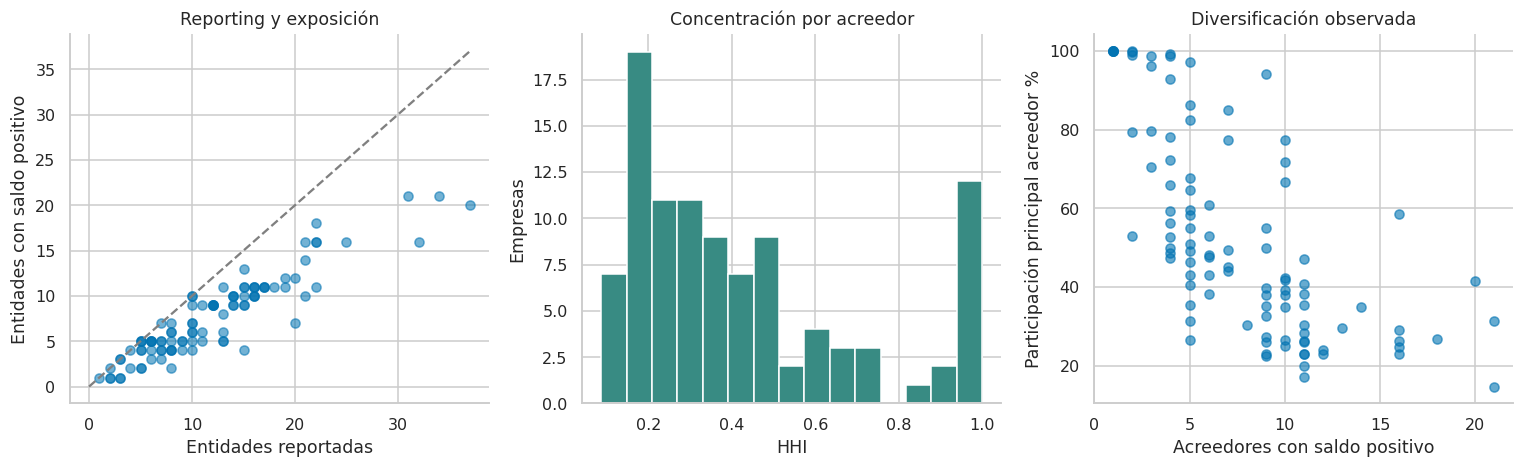

,razon_social,n_entidades_reportadas,n_entidades_con_saldo_positivo,hhi_deuda_positiva,participacion_acreedor_principal
23,Asociación de Cooperativas Argentinas CL,25,16.000,0.147,0.248
47,Grupo Peñaflor S.A.U.,18,11.000,0.231,0.408
71,Molfino Hermanos S.A.,15,4.000,0.344,0.487
95,Vicentin S.A.I.C. / Nueva Vicentin Argentina,4,2.000,0.998,0.999
119,Seaboard Energías Renovables y Alimentos S.R.L.,7,5.000,0.378,0.464
143,Ledesma S.A.A.I.,32,16.000,0.145,0.230
167,Buyatti S.A.I.C.A.,15,9.000,0.187,0.273
191,Manfrey Coop. de Tamberos de Comercialización ...,11,5.000,0.402,0.551
215,Establecimiento Las Marías S.A.C.I.F. y A.,20,12.000,0.157,0.230
239,MOLINO VICTORIA S.A.,6,5.000,0.406,0.584


Entre las empresas activas del último mes, la mediana de acreedores con saldo positivo es **7.0**, y la mediana de participación del acreedor principal es **47.3%**.

In [14]:
fig,axes=plt.subplots(1,3,figsize=(14,4.4))
axes[0].scatter(cl.n_entidades_reportadas,cl.n_entidades_con_saldo_positivo,alpha=.55)
mx=cl.n_entidades_reportadas.max();axes[0].plot([0,mx],[0,mx],ls='--',color='gray')
axes[0].set(xlabel='Entidades reportadas',ylabel='Entidades con saldo positivo',title='Reporting y exposición')
axes[1].hist(cl_active.hhi_deuda_positiva,bins=15,color='#388b83',edgecolor='white')
axes[1].set(xlabel='HHI',ylabel='Empresas',title='Concentración por acreedor')
axes[2].scatter(cl_active.n_entidades_con_saldo_positivo,100*cl_active.participacion_acreedor_principal,alpha=.6)
axes[2].set(xlabel='Acreedores con saldo positivo',ylabel='Participación principal acreedor %',title='Diversificación observada')
figsave(fig,'C3_acreedores_hhi')
table(cl[['razon_social','n_entidades_reportadas','n_entidades_con_saldo_positivo','hhi_deuda_positiva','participacion_acreedor_principal']],
      'C3_acreedores_ultimo',rows=12)
say(f'Entre las empresas activas del último mes, la mediana de acreedores con saldo positivo es '
    f'**{cl_active.n_entidades_con_saldo_positivo.median():.1f}**, y la mediana de participación del acreedor principal '
    f'es **{100*cl_active.participacion_acreedor_principal.median():.1f}%**.')

## C3. ¿Cómo se distribuye la situación crediticia y qué saldo corresponde a cada categoría?

Se presentan dos ponderaciones diferentes: (1) empresas clasificadas por su peor situación activa, una empresa = una observación; (2) saldos de las filas distribuidos por situación, un peso = una unidad de exposición. Un saldo pequeño en una categoría alta puede cambiar el máximo de la empresa sin dominar su exposición total. No se usa promedio aritmético de categorías ordinales.

El estado sin saldo positivo aparece por separado y no se numera como situación 0. Las categorías se muestran con su código informado; este EDA no redefine su interpretación regulatoria.

24 filas en outputs/tablas/C4_empresas_por_estado.csv; vista: primeras 16.
24 filas en outputs/tablas/C4_saldo_por_situacion_pct.csv; vista: primeras 16.


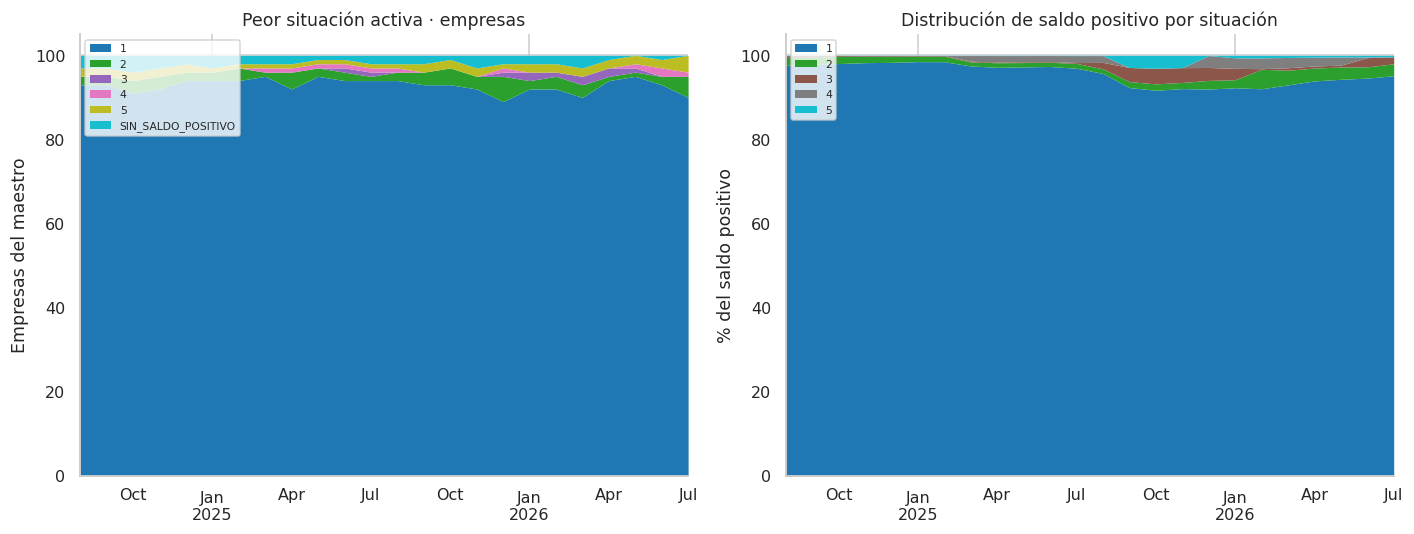

estado_eda,fecha,1,2,3,4,5,SIN_SALDO_POSITIVO
0,2024-08-01,93,2,0,0,2,3
1,2024-09-01,93,2,0,0,2,3
2,2024-10-01,91,3,0,0,2,4
3,2024-11-01,92,3,0,0,2,3
4,2024-12-01,94,2,0,0,2,2
5,2025-01-01,94,2,0,0,1,3
6,2025-02-01,94,3,0,0,1,2
7,2025-03-01,95,1,0,1,1,2
8,2025-04-01,92,4,0,1,1,2
9,2025-05-01,95,2,0,1,1,1


categoria_situacion,fecha,1,2,3,4,5
0,2024-08-01,97.600,1.915,0.406,0.000,0.079
1,2024-09-01,97.836,1.726,0.367,0.000,0.071
2,2024-10-01,98.043,1.702,0.193,0.000,0.062
3,2024-11-01,98.258,1.510,0.175,0.000,0.056
4,2024-12-01,98.327,1.445,0.172,0.000,0.056
5,2025-01-01,98.499,1.297,0.155,0.000,0.050
6,2025-02-01,98.477,1.314,0.158,0.000,0.051
7,2025-03-01,97.472,0.961,0.158,1.360,0.050
8,2025-04-01,97.154,1.085,0.178,1.527,0.057
9,2025-05-01,97.251,1.033,0.174,1.488,0.055


En el último mes, **10** empresas tienen alguna exposición con situación 2 o superior. El saldo en situaciones 3+ representa **2.01%** del saldo positivo del panel.

In [15]:
state_counts=pd.crosstab(cp.fecha,cp.estado_eda)
state_order=[x for x in ['1','2','3','4','5','6','ACTIVA_SITUACION_DESCONOCIDA','SIN_SALDO_POSITIVO','SIN_OBSERVACION'] if x in state_counts]
state_counts=state_counts[state_order]
debt_categories=c_active.assign(categoria_situacion=c_active.situacion.map({i:str(i) for i in range(1,7)}).fillna('DESCONOCIDA'))
debt_state=debt_categories.groupby(['fecha','categoria_situacion']).monto_miles_pesos.sum().unstack(fill_value=0)
debt_share=debt_state.div(debt_state.sum(axis=1),axis=0)*100
fig,axes=plt.subplots(1,2,figsize=(13,5))
state_counts.plot.area(ax=axes[0],linewidth=0,colormap='tab10')
debt_share.plot.area(ax=axes[1],linewidth=0,colormap='tab10')
axes[0].set(title='Peor situación activa · empresas',ylabel='Empresas del maestro',xlabel='')
axes[1].set(title='Distribución de saldo positivo por situación',ylabel='% del saldo positivo',xlabel='')
for ax in axes:ax.legend(fontsize=7,loc='upper left')
figsave(fig,'C4_situacion_empresas_saldos')
table(state_counts.reset_index(),'C4_empresas_por_estado')
table(debt_share.reset_index(),'C4_saldo_por_situacion_pct')
any_2=c_active.loc[c_active.fecha.eq(cp.fecha.max()) & c_active.situacion.isin([2,3,4,5,6]),'cuit_normalizado'].nunique()
say(f'En el último mes, **{any_2}** empresas tienen alguna exposición '
    f'con situación 2 o superior. El saldo en situaciones 3+ representa '
    f'**{100*c_active.loc[c_active.fecha.eq(cp.fecha.max()) & c_active.situacion.ge(3),"monto_miles_pesos"].sum()/cl_active.deuda_total_positiva.sum():.2f}%** '
    'del saldo positivo del panel.')

## C4. ¿Qué transiciones y persistencia observamos?

La matriz de riesgo usa pares adyacentes con situación activa conocida en ambos meses. Empeora = aumenta el código ordinal; mejora = disminuye; permanece = no cambia. El paso de sin saldo positivo a situación 1 se informa como cambio de estado de exposición y no como deterioro. Se exporta también la matriz de estados completa para no perder esas entradas y salidas.

Las filas de la matriz porcentual se normalizan por cantidad de pares que parten de la categoría, no por empresas únicas. Hay observaciones repetidas por CUIT y las categorías poco frecuentes tienen escaso soporte.

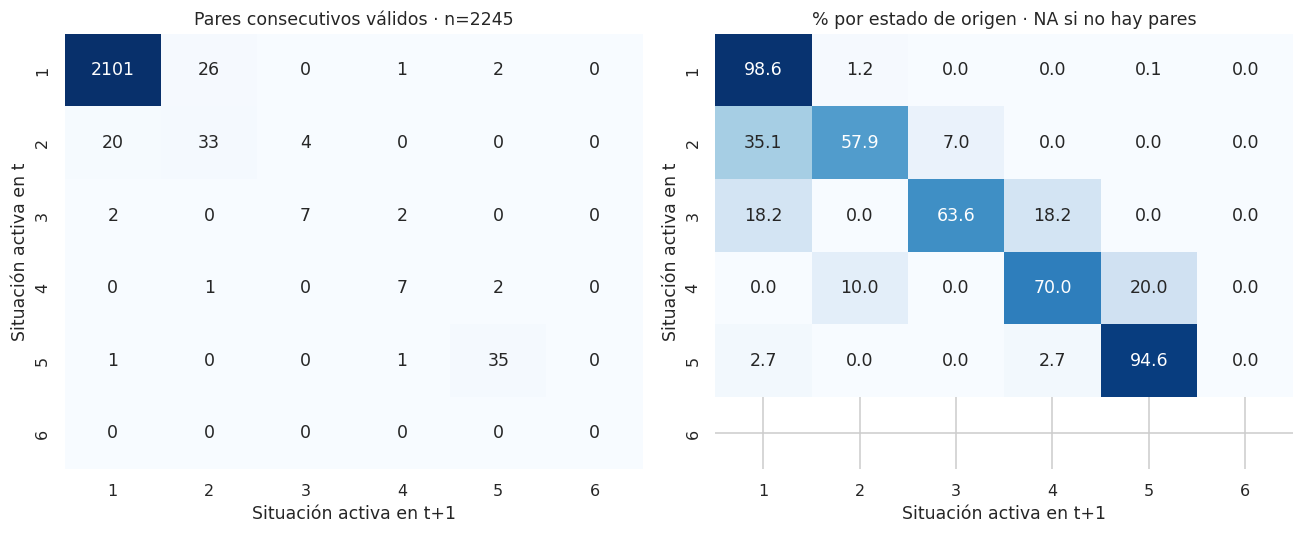

situacion_max_activa,situacion_origen,1,2,3,4,5,6
0,1,2101,26,0,1,2,0
1,2,20,33,4,0,0,0
2,3,2,0,7,2,0,0
3,4,0,1,0,7,2,0
4,5,1,0,0,1,35,0
5,6,0,0,0,0,0,0


estado_eda,estado_origen,1,2,3,4,5,SIN_SALDO_POSITIVO
0,1,2101,26,0,1,2,8
1,2,20,33,4,0,0,0
2,3,2,0,7,2,0,0
3,4,0,1,0,7,2,0
4,5,1,0,0,1,35,0
5,SIN_SALDO_POSITIVO,11,0,0,0,0,36


,evento,n_pares,pct_pares_validos
0,Permanece,2183,97.238
1,Empeora,37,1.648
2,Mejora,25,1.114


**2300** pares mensuales observados; **2245** con riesgo activo conocido en ambos extremos. Hay **37** empeoramientos descriptivos y **11** entradas desde sin saldo positivo a una situación activa. Esta definición descriptiva no modifica el target exploratorio almacenado.

In [16]:
pairs,risk,risk_matrix,state_matrix=eda.transitions_c(cp)
row_pct=risk_matrix.div(risk_matrix.sum(axis=1).replace(0,np.nan),axis=0)*100
fig,axes=plt.subplots(1,2,figsize=(12,5))
sns.heatmap(risk_matrix,annot=True,fmt='d',cmap='Blues',ax=axes[0],cbar=False)
sns.heatmap(row_pct,annot=True,fmt='.1f',vmin=0,vmax=100,cmap='Blues',ax=axes[1],cbar=False)
for ax in axes:ax.set(xlabel='Situación activa en t+1',ylabel='Situación activa en t')
axes[0].set_title(f'Pares consecutivos válidos · n={len(risk)}')
axes[1].set_title('% por estado de origen · NA si no hay pares')
figsave(fig,'C5_transiciones')
table(risk_matrix.reset_index(),'C5_matriz_conteos')
table(state_matrix.reset_index(),'C5_matriz_estados_exposicion',rows=12)
event_counts=risk.evento.value_counts().rename_axis('evento').reset_index(name='n_pares')
event_counts['pct_pares_validos']=100*event_counts.n_pares/len(risk)
table(event_counts,'C5_eventos')
eda.save_table(risk[['cuit_normalizado','razon_social','fecha_origen','fecha','situacion_origen','situacion_max_activa','evento']],
               'C5_transiciones_detalle',OUT)
eda.save_table(pairs[['cuit_normalizado','fecha_origen','fecha','estado_origen','estado_eda']], 'C5_estados_detalle',OUT)
inflows=((pairs.estado_origen=='SIN_SALDO_POSITIVO') & pairs.estado_eda.isin([str(x) for x in range(1,7)])).sum()
say(f'**{len(pairs)}** pares mensuales observados; **{len(risk)}** con riesgo activo conocido en ambos extremos. '
    f'Hay **{int(risk.evento.eq("Empeora").sum())}** empeoramientos descriptivos y '
    f'**{int(inflows)}** entradas desde sin saldo positivo a una situación activa. '
    'Esta definición descriptiva no modifica el target exploratorio almacenado.')

## C5. ¿Qué diferencias descriptivas se observan entre subsectores?

Cada empresa se cuenta una vez dentro de cada subsector al que pertenece. Los totales entre subsectores no son aditivos: las 102 pertenencias corresponden a 100 CUIT. El gráfico usa el último mes y muestra n por subsector. La deuda mediana y las proporciones tienen soporte desigual; se evita tratarlas como estimaciones de la Agroindustria argentina.

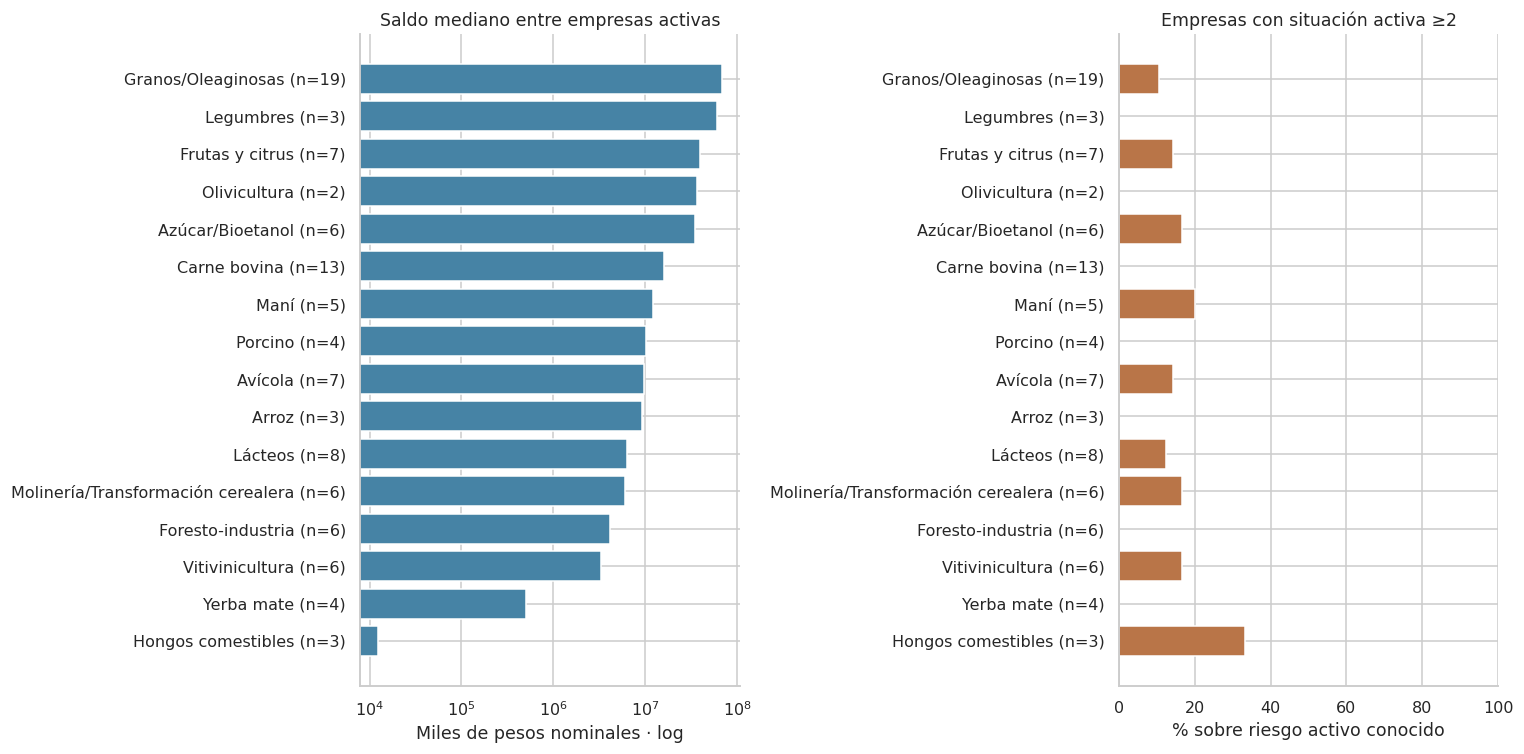

,subsector,n_empresas,n_observadas,n_activas,n_riesgo_conocido,n_situacion_2_mas,mediana_deuda_activa_miles,mediana_acreedores_activos,mediana_hhi,pct_situacion_2_mas
7,Hongos comestibles,3,3,3,3,1,"12,252.000",2.000,0.502,33.333
15,Yerba mate,4,4,4,4,0,"507,866.000",4.000,0.698,0.000
14,Vitivinicultura,6,6,6,6,1,"3,294,752.000",6.000,0.384,16.667
4,Foresto-industria,6,6,6,6,0,"4,128,760.500",4.500,0.505,0.000
11,Molinería/Transformación cerealera,6,6,6,6,1,"5,947,245.500",7.000,0.332,16.667
9,Lácteos,8,8,8,8,1,"6,360,044.000",6.000,0.507,12.500
0,Arroz,3,3,3,3,0,"9,249,372.000",9.000,0.166,0.000
1,Avícola,7,7,7,7,1,"9,591,533.000",10.000,0.347,14.286
13,Porcino,4,4,4,4,0,"10,099,889.000",4.500,0.623,0.000
10,Maní,5,5,5,5,1,"12,190,656.000",9.000,0.346,20.000


In [17]:
sector_panel=cp.merge(links[['cuit_normalizado','subsector']],on='cuit_normalizado',how='left',validate='many_to_many')
sl=sector_panel[sector_panel.fecha.eq(cp.fecha.max())]
sector=sl.groupby('subsector').agg(n_empresas=('cuit_normalizado','nunique'),
    n_observadas=('mes_observado','sum'),n_activas=('empresa_con_deuda_activa','sum'),
    n_riesgo_conocido=('situacion_max_activa','count'),
    n_situacion_2_mas=('situacion_max_activa',lambda s:s.ge(2).sum()),
    mediana_deuda_activa_miles=('deuda_total_positiva',lambda s:s[s>0].median()),
    mediana_acreedores_activos=('n_entidades_con_saldo_positivo','median'),
    mediana_hhi=('hhi_deuda_positiva','median')).reset_index()
sector['pct_situacion_2_mas']=100*sector.n_situacion_2_mas/sector.n_riesgo_conocido.replace(0,np.nan)
sector=sector.sort_values('mediana_deuda_activa_miles')
fig,axes=plt.subplots(1,2,figsize=(14,7))
labels=sector.subsector+' (n='+sector.n_empresas.astype(str)+')'
y=np.arange(len(sector))
axes[0].barh(y,sector.mediana_deuda_activa_miles,color='#4683a5')
axes[0].set_yticks(y,labels);axes[0].set_xscale('log')
axes[0].set(title='Saldo mediano entre empresas activas',xlabel='Miles de pesos nominales · log')
axes[1].barh(y,sector.pct_situacion_2_mas,color='#b97548')
axes[1].set_yticks(y,labels);axes[1].set(title='Empresas con situación activa ≥2',xlabel='% sobre riesgo activo conocido',xlim=(0,100))
figsave(fig,'C6_subsectores')
table(sector,'C6_comparacion_subsectores',rows=20)
eda.save_table(sector_panel,'C_empresa_subsector_mes_analitica',OUT)

## C6. ¿Qué trayectorias empresariales resultan especialmente informativas?

El mapa muestra todas las empresas ordenadas por peor situación activa observada y saldo del último mes. Se añade una selección reproducible de hasta seis trayectorias: tres por mayor saldo final y tres por mayor cantidad de cambios activos de situación. Los criterios se explicitan para que la selección de casos no reemplace la descripción del panel completo.

La escala de saldos es logarítmica. Los meses sin saldo positivo no se dibujan como deuda positiva; los meses sin observación permanecen ausentes. Los nombres identifican personas jurídicas del maestro.

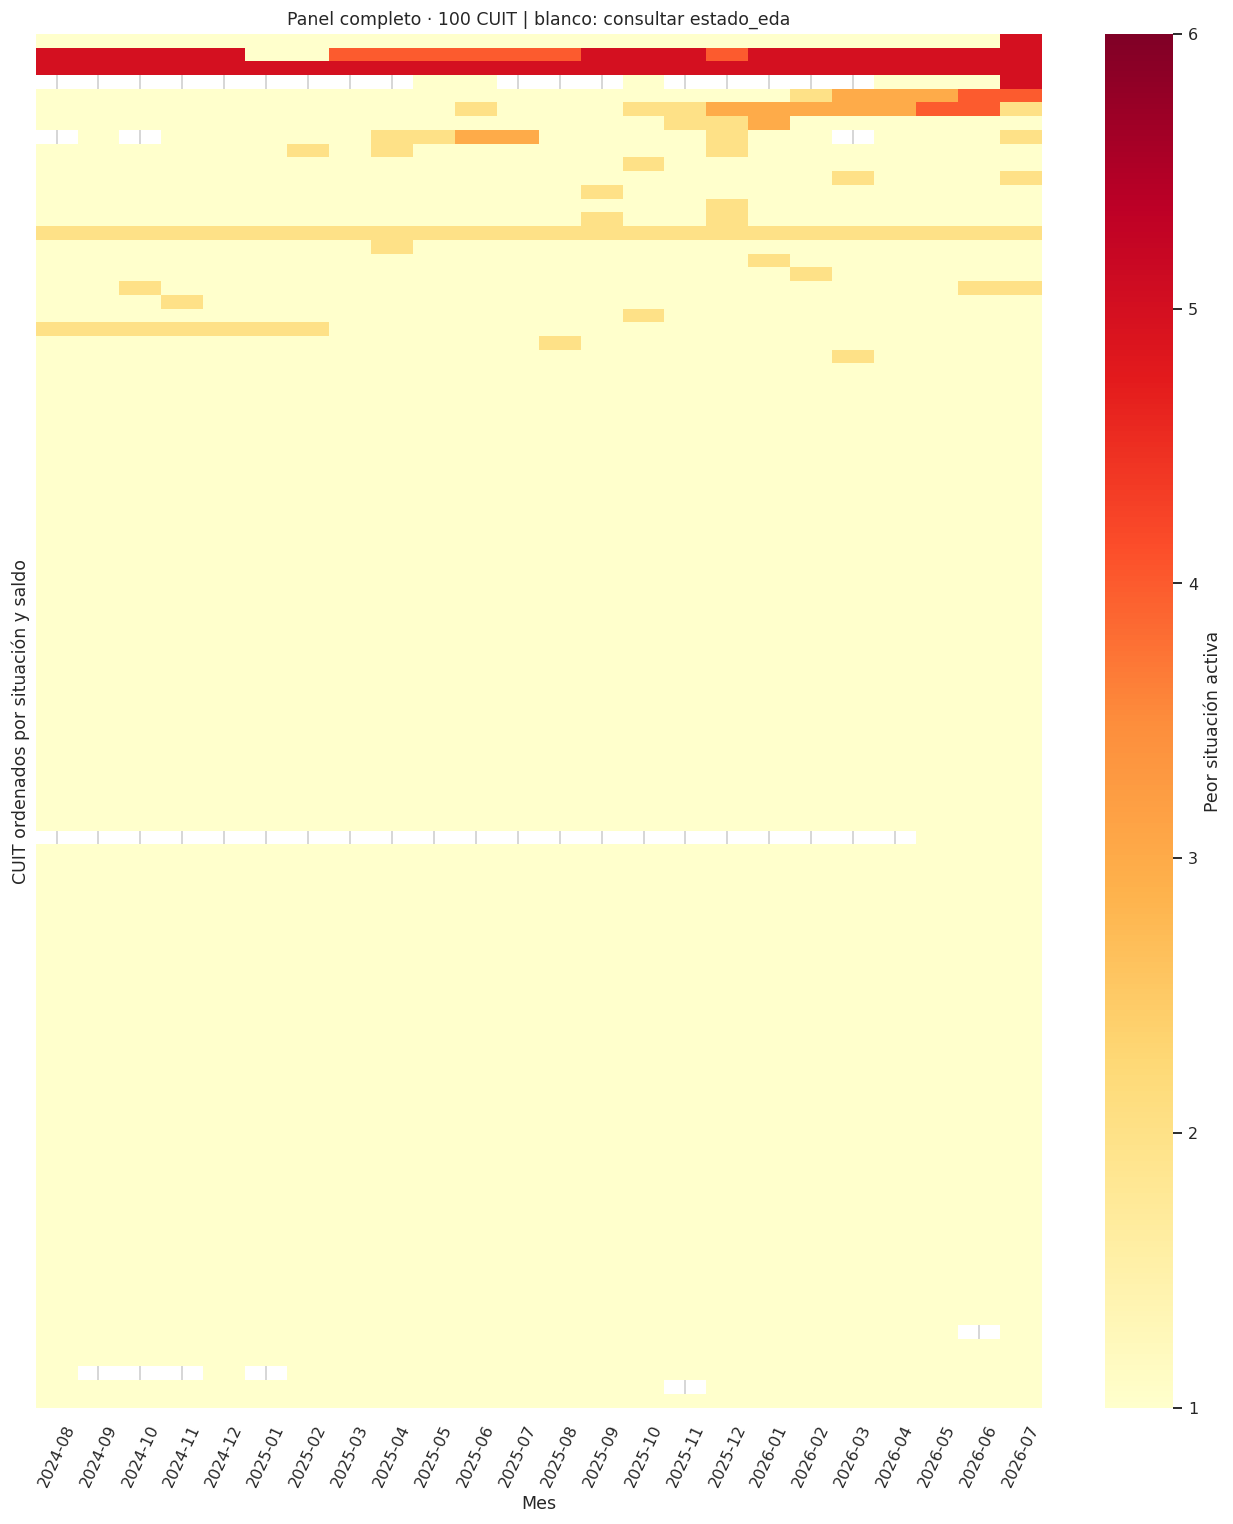

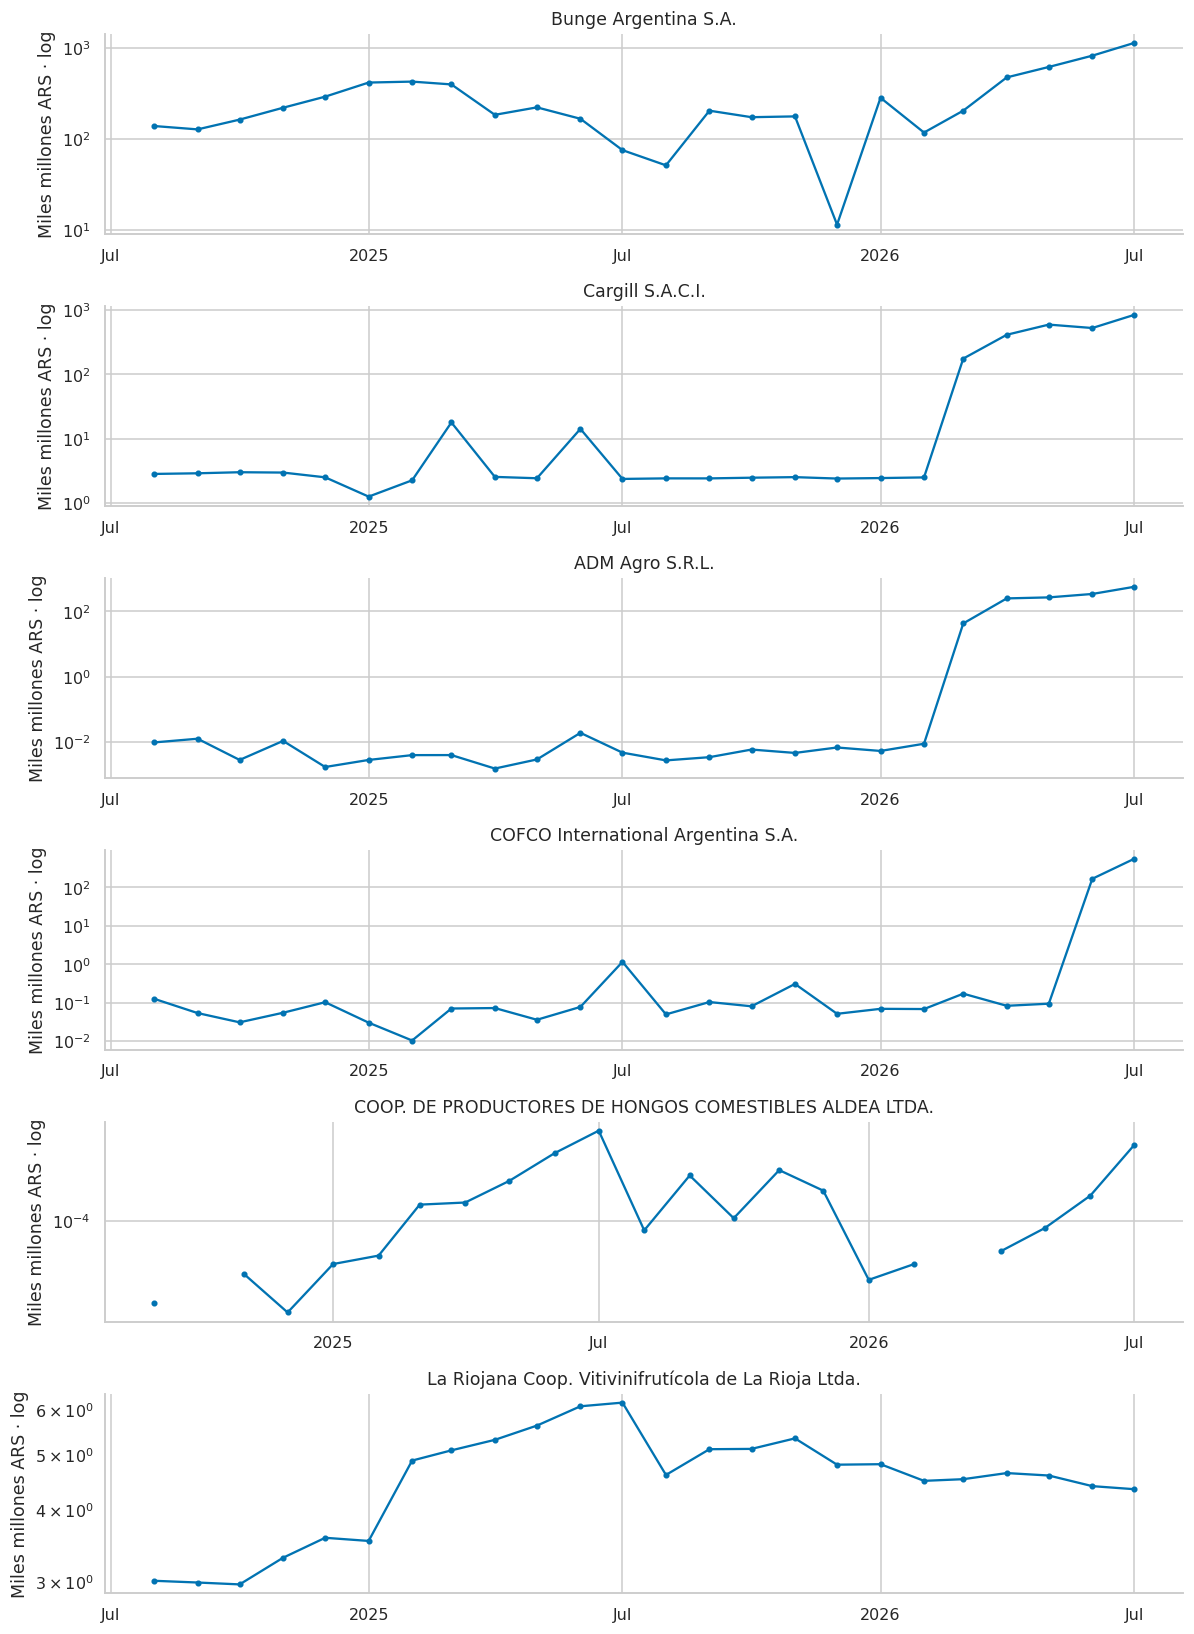

,cuit_normalizado,razon_social,motivo
0,30700869918,Bunge Argentina S.A.,mayor saldo final
1,30506792165,Cargill S.A.C.I.,mayor saldo final
2,30621973173,ADM Agro S.R.L.,mayor saldo final
3,33506737449,COFCO International Argentina S.A.,más cambios de situación activa
4,30712473963,COOP. DE PRODUCTORES DE HONGOS COMESTIBLES ALD...,más cambios de situación activa
5,30632951716,La Riojana Coop. Vitivinifrutícola de La Rioja...,más cambios de situación activa


In [18]:
wide_state=cp.pivot(index='cuit_normalizado',columns='fecha',values='situacion_max_activa')
order_frame=cp.groupby('cuit_normalizado').situacion_max_activa.max().rename('peor').to_frame().join(cl.set_index('cuit_normalizado').deuda_total_positiva)
order_frame=order_frame.sort_values(['peor','deuda_total_positiva'],ascending=[False,False])
name_map=master.set_index('cuit_normalizado').razon_social
fig,ax=plt.subplots(figsize=(12,14))
sns.heatmap(wide_state.reindex(order_frame.index),mask=wide_state.reindex(order_frame.index).isna(),
            vmin=1,vmax=6,cmap='YlOrRd',ax=ax,yticklabels=False,cbar_kws={'label':'Peor situación activa'})
ax.set_xticks(np.arange(len(wide_state.columns))+.5,[d.strftime('%Y-%m') for d in wide_state.columns],rotation=65)
ax.set(title=f'Panel completo · {len(master)} CUIT | blanco: consultar estado_eda',xlabel='Mes',ylabel='CUIT ordenados por situación y saldo')
figsave(fig,'C7_mapa_trayectorias')
change_counts=risk[risk.evento.ne('Permanece')].groupby('cuit_normalizado').size().sort_values(ascending=False)
ids=list(cl_active.nlargest(3,'deuda_total_positiva').cuit_normalizado)
ids=list(dict.fromkeys(ids+list(change_counts.head(3).index)))
fig,axes=plt.subplots(len(ids),1,figsize=(11,2.5*len(ids)),squeeze=False)
selection=[]
for ax,cuit in zip(axes.flat,ids):
    g=cp[cp.cuit_normalizado.eq(cuit)].sort_values('fecha')
    positive=g.deuda_total_positiva.where(g.deuda_total_positiva.gt(0))
    ax.plot(g.fecha,positive/1e6,marker='o',markersize=3)
    ax.set_yscale('log');ax.set(ylabel='Miles millones ARS · log',title=name_map[cuit],xlabel='')
    selection.append({'cuit_normalizado':cuit,'razon_social':name_map[cuit],
                      'motivo':'mayor saldo final' if cuit in list(cl_active.nlargest(3,'deuda_total_positiva').cuit_normalizado) else 'más cambios de situación activa'})
figsave(fig,'C8_casos_trayectorias')
table(pd.DataFrame(selection),'C8_seleccion_casos')
eda.save_table(wide_state.reset_index(),'C7_mapa_situaciones',OUT)

# D. Síntesis transversal y cierre del EDA

Los tres bloques responden preguntas complementarias, con límites diferentes. A describe series agregadas; B describe registros de oferta observados, sin volúmenes; C describe saldos de un panel intencional. No se deben interpretar conjuntamente como etapas de una misma operación crediticia. La ausencia de solapamiento B–C y de una llave de producto estable impide atribuir a ofertas publicadas cambios de deuda empresaria.

### Hipótesis para evaluar después del EDA
- **A:** comprobar si las asociaciones entre variaciones nominales, inflación y tasas persisten con medidas reales, ventanas alternativas y cambios de metodología. Las correlaciones aquí no seleccionan por sí solas variables de un modelo.
- **B:** explorar modelos separados por denominación, familia y modalidad; comparar sensibilidad al peso de cada entidad, antigüedad y requisitos. La oferta máxima publicada no equivale al costo realizado.
- **C:** evaluar cómo la concentración, la persistencia de situaciones y los cambios de exposición se relacionan con futuros eventos, con validación temporal y atención a la escasez de transiciones. Definir el target después de revisar estos resultados.

### Límites pendientes para ampliar el análisis
1. Ingesta histórica cambiaria y stocks monetarios/depósitos, si se mantienen esas preguntas.
2. Más snapshots B; resolución individual de ofertas para tracking de productos.
3. Más períodos C y enriquecimiento estructurado por tamaño/región, si se incorporan esas comparaciones.
4. Revisar los supuestos de comparabilidad real, indexación y cambios metodológicos antes de modelar.
5. Resolver la escala monetaria absoluta de los stocks A: el catálogo amplio ofrece señales de inconsistencia entre unidades declaradas. Las conversiones a ARS y la comparación de niveles A–C quedan pendientes.

Estos puntos limitan preguntas específicas; los bloques implementados pueden reproducirse con el paquete actual.

In [19]:
findings = [
    {'base':'A','hallazgo':f'Al {stocks.dropna().index.max():%Y-%m}, {stock_summary.ultimo.idxmax()} concentra {stock_summary.participacion_ultimo_pct.max():.1f}% del stock de categorías cubiertas.',
     'limite':'Composición del universo cubierto; magnitudes nominales.'},
    {'base':'A','hallazgo':f'Desde {composition.index[0]:%Y-%m}, {delta_shares.idxmax()} gana {delta_shares.max():.2f} pp de participación.',
     'limite':'No mide crecimiento real ni identifica causas.'},
    {'base':'B','hallazgo':f'Personales en pesos a tasa fija: mediana TEA {bp.tea.median():.2f}%, IQR {bp.tea.quantile(.25):.2f}–{bp.tea.quantile(.75):.2f}%, n={bp.tea.count()}.',
     'limite':'Registros de tasas máximas publicadas, sin ponderación por volumen ni homogeneidad completa de condiciones.'},
    {'base':'C','hallazgo':f'Último mes: {len(cl_active)}/{int(cl.mes_observado.sum())} empresas con saldo positivo; las diez de mayor saldo concentran {top10_share:.1f}%.',
     'limite':'Panel intencional; concentración de deuda observada, no del mercado nacional.'},
    {'base':'C','hallazgo':f'Mediana de acreedores activos: {cl_active.n_entidades_con_saldo_positivo.median():.1f}; mediana de participación del principal: {100*cl_active.participacion_acreedor_principal.median():.1f}%.',
     'limite':'Exposición sobre saldo positivo; no mide por sí sola solvencia ni estrés.'},
    {'base':'C','hallazgo':f'{int(risk.evento.eq("Empeora").sum())} empeoramientos entre {len(risk)} pares con situación activa conocida.',
     'limite':'Diagnóstico descriptivo; target exploratorio previo intacto.'},
    {'base':'ABC','hallazgo':f'{len(overlap_bc)} meses de solapamiento B–C.',
     'limite':'Síntesis conceptual; sin join físico ni inferencia causal entre bloques.'},
]
table(pd.DataFrame(findings),'D_hallazgos',rows=10)
validation = {
    'entradas_sin_cambios':SOURCE_HASHES == eda.fingerprint(ROOT),
    'clave_c_empresa_mes_unica':not cp.duplicated(['cuit_normalizado','fecha']).any(),
    'universo_c_conservado':set(master.cuit_normalizado)==set(cp.cuit_normalizado),
    'sin_saldo_situacion_na':cp.loc[cp.deuda_total_positiva.eq(0),'situacion_max_activa'].isna().all(),
    'sin_saldo_hhi_na':cp.loc[cp.deuda_total_positiva.eq(0),'hhi_deuda_positiva'].isna().all(),
    'activos_no_superan_reportados':(cp.loc[cp.mes_observado,'n_entidades_con_saldo_positivo']<=cp.loc[cp.mes_observado,'n_entidades_reportadas']).all(),
    'deuda_positiva_reconcilia':bool(np.isclose(cp.deuda_total_positiva.sum(),c_active.monto_miles_pesos.sum())),
    'porcentajes_exposicion_suman_100':bool(np.allclose(cp.loc[cp.deuda_total_positiva.gt(0),
        ['pct_deuda_situacion_1','pct_deuda_situacion_2','pct_deuda_situacion_3_mas','pct_deuda_situacion_desconocida']].sum(axis=1),100)),
    'transiciones_solo_meses_consecutivos':bool(risk.adyacente.all()),
}
validation={k:bool(v) for k,v in validation.items()}
assert all(validation.values()), validation
table(pd.DataFrame(validation.items(),columns=['control','resultado']),'D_validacion',rows=20)
metadata={'version':'1.0','run_c':run_c.name,'snapshot_b_ultimo':latest_sid,
          'n_snapshots_b':int(b.snapshot_id.nunique()),'runtime':eda.runtime_metadata(),
          'source_sha256':SOURCE_HASHES,'validacion':validation,
          'catalogo_sha256':hashlib.sha256((ROOT/'config/catalogo_base_a.csv').read_bytes()).hexdigest(),
          'codigo_sha256':{name:hashlib.sha256((ROOT/name).read_bytes()).hexdigest() for name in ['lib/common.py','base_a.py','base_b.py','base_c.py']}}
(OUT/'trazabilidad.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
say(f'**Ejecución completada:** {len(list((OUT/"figuras").glob("*.png")))} figuras y '
    f'{len(list((OUT/"tablas").glob("*.csv")))} tablas. Entradas verificadas mediante SHA-256.')

,base,hallazgo,limite
0,A,"Al 2026-06, Personas humanas concentra 47.1% d...",Composición del universo cubierto; magnitudes ...
1,A,"Desde 2024-01, Personas humanas gana 1.11 pp d...",No mide crecimiento real ni identifica causas.
2,B,Personales en pesos a tasa fija: mediana TEA 2...,"Registros de tasas máximas publicadas, sin pon..."
3,C,Último mes: 100/100 empresas con saldo positiv...,Panel intencional; concentración de deuda obse...
4,C,Mediana de acreedores activos: 7.0; mediana de...,Exposición sobre saldo positivo; no mide por s...
5,C,37 empeoramientos entre 2245 pares con situaci...,Diagnóstico descriptivo; target exploratorio p...
6,ABC,0 meses de solapamiento B–C.,Síntesis conceptual; sin join físico ni infere...


,control,resultado
0,entradas_sin_cambios,True
1,clave_c_empresa_mes_unica,True
2,universo_c_conservado,True
3,sin_saldo_situacion_na,True
4,sin_saldo_hhi_na,True
5,activos_no_superan_reportados,True
6,deuda_positiva_reconcilia,True
7,porcentajes_exposicion_suman_100,True
8,transiciones_solo_meses_consecutivos,True


**Ejecución completada:** 20 figuras y 42 tablas. Entradas verificadas mediante SHA-256.